# DA3METRIC-LARGE Ablation Study — Deep Analysis Notebook
**Fully-Supervised Fine-Tuning on KITTI Eigen-Split**

This notebook analyses the HPT ablation study results from `DA3_supervised_FT_Ablation_HPT_v6.ipynb`.

**Focus:** `val_rmse` (unscaled, epoch-wise) and `test_rmse` (unscaled, pixel-weighted).  
**Skipped:** median / mean / affine scale variants.  
**Groups:** Loss functions · Architecture · Augmentation · Optimizer/Scheduler

---
> **Run this notebook from the same machine** where the ablation was executed so all CSV paths are valid.


In [1]:
import os, glob, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
from matplotlib.gridspec import GridSpec
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
warnings.filterwarnings('ignore')
matplotlib.rcParams.update({
    'figure.dpi': 130,
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'legend.fontsize': 8.5,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
})

# ─── CONFIGURE PATHS ────────────────────────────────────────────────────────
RESULTS_DIR = "/STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/results"
PLOT_DIR    = "/STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis"
os.makedirs(PLOT_DIR, exist_ok=True)

SUMMARY_CSV  = os.path.join(RESULTS_DIR, "ablation_summary.csv")
ABLATION_EPOCHS = 5
PATIENCE        = 3

LR_TAGS    = ['lr=0.0001', 'lr=5e-05', 'lr=2e-05']
LR_DISPLAY = {'lr=0.0001': 'LR=1e-4', 'lr=5e-05': 'LR=5e-5', 'lr=2e-05': 'LR=2e-5'}
LR_COLORS  = {'lr=0.0001': '#e74c3c', 'lr=5e-05': '#2980b9', 'lr=2e-05': '#27ae60'}
LR_MARKERS = {'lr=0.0001': 'o', 'lr=5e-05': 's', 'lr=2e-05': '^'}

GROUPS = {
    'LOSS':  {'prefix': 'loss_',  'label': 'Loss Function'},
    'ARCH':  {'prefix': 'arch_',  'label': 'Architecture'},
    'AUG':   {'prefix': 'aug_',   'label': 'Augmentation'},
    'OPTIM': {'prefix': 'optim_', 'label': 'Optimizer/Scheduler'},
}

# ── Readable short names ─────────────────────────────────────────────────────
SHORT_NAME = {
    'loss_silog':              'SILog',
    'loss_berhu':              'BerHu',
    'loss_combined_base':      'Combined\n(baseline)',
    'loss_vnl':                'VNL',
    'loss_log_l1':             'Log-L1',
    'loss_ssim_l1':            'SSIM+L1',
    'loss_affine_invariant':   'Affine-Inv.',
    'loss_robust_cauchy':      'Cauchy',
    'loss_masked_depth':       'MaskedDepth\n(DA3 L_D)',
    'loss_mae_canonical':      'MAE-Canon.\n(DepthPro)',
    'loss_eg_ssi':             'EG-SSI\n(UniDepthV2)',
    'loss_tgm':                'TGM\n(VideoDA)',
    'loss_da3_video_combined': 'DA3-Video\nCombined',
    'arch_decoder_only':       'Decoder-Only',
    'arch_last2_blocks':       'Last-2-Blocks',
    'arch_full':               'Full FT',
    'aug_none':                'No Aug',
    'aug_flip':                'Flip-Only',
    'aug_base':                'Base (flip+jitter)',
    'aug_full':                'Full (flip+jitter+crop)',
    'optim_adamw_cosine_warmup': 'AdamW\n+CosWarm',
    'optim_adam_cosine_warmup':  'Adam\n+CosWarm',
    'optim_sgd_cosine_warmup':   'SGD\n+CosWarm',
    'optim_adamw_onecycle':      'AdamW\n+OneCycle',
    'optim_adamw_step':          'AdamW\n+StepLR',
}

print(f"✓ Setup complete")
print(f"  Results dir : {RESULTS_DIR}")
print(f"  Analysis plots → {PLOT_DIR}")


✓ Setup complete
  Results dir : /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/results
  Analysis plots → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis


## 1 · Load Data

In [2]:
# ── Summary CSV ─────────────────────────────────────────────────────────────
summary_df = pd.read_csv(SUMMARY_CSV)
print(f"Summary: {len(summary_df)} configs")
print(summary_df[['config','unscaled_rmse','winner_hpt_tag','winner_epoch']].to_string(index=False))

# ── Per-config history CSVs ──────────────────────────────────────────────────
history_dfs = {}
hpt_dfs     = {}

for cfg in summary_df['config']:
    hist_path = os.path.join(RESULTS_DIR, f"history_{cfg}.csv")
    hpt_path  = os.path.join(RESULTS_DIR, f"hpt_sweep_{cfg}.csv")
    if os.path.exists(hist_path):
        history_dfs[cfg] = pd.read_csv(hist_path)
    else:
        print(f"  [WARN] Missing history for {cfg}")
    if os.path.exists(hpt_path):
        hpt_dfs[cfg] = pd.read_csv(hpt_path)
    else:
        print(f"  [WARN] Missing hpt_sweep for {cfg}")

print(f"\nLoaded {len(history_dfs)} history CSVs, {len(hpt_dfs)} hpt_sweep CSVs")

# ── Build group membership ────────────────────────────────────────────────────
group_configs = {}
for grp, meta in GROUPS.items():
    group_configs[grp] = sorted(
        [c for c in summary_df['config'] if c.startswith(meta['prefix'])]
    )
    print(f"  {grp:6s}: {group_configs[grp]}")


Summary: 25 configs
                   config  unscaled_rmse winner_hpt_tag  winner_epoch
               loss_silog       2.537587       lr=2e-05             5
               loss_berhu       2.586817       lr=5e-05             5
       loss_combined_base       2.526200       lr=2e-05             4
                 loss_vnl       4.356280       lr=5e-05             1
              loss_log_l1       2.804235      lr=0.0001             3
             loss_ssim_l1       2.620148       lr=5e-05             4
    loss_affine_invariant       2.987027      lr=0.0001             5
       loss_robust_cauchy       2.760158       lr=2e-05             5
        loss_masked_depth       2.672515       lr=2e-05             3
       loss_mae_canonical       2.499683       lr=5e-05             3
              loss_eg_ssi       2.673856       lr=2e-05             1
                 loss_tgm       6.554527      lr=0.0001             4
  loss_da3_video_combined       2.910073       lr=2e-05             2


## 2 · Helper Functions

In [3]:
def get_config_history(cfg, lr_tag=None):
    """Return history DataFrame for a config, optionally filtered to one LR tag."""
    df = history_dfs.get(cfg)
    if df is None:
        return pd.DataFrame()
    if lr_tag:
        df = df[df['hpt_tag'] == lr_tag].copy()
    return df.sort_values('epoch').reset_index(drop=True)


def trajectory_quality(val_rmse_series, ablation_epochs=5):
    """
    Characterise the training trajectory.
    Returns dict with quality metrics and a label.
    
    Labels:
      "Steady Descent"  — val RMSE improved ≥70 % of epochs, best at last or 2nd-last
      "Good Convergence"— val RMSE improved ≥50 % of epochs
      "Early-Stop OK"   — early stopped but best epoch was in the 1st half
      "Bouncy / Poor"   — erratic or very low improvement rate
    """
    s = list(val_rmse_series)
    n = len(s)
    if n == 0:
        return {'label': 'No Data', 'improvement_rate': 0, 'best_epoch': 0,
                'n_epochs': 0, 'early_stopped': False, 'trend_slope': 0}

    improvements = sum(1 for i in range(1, n) if s[i] < s[i-1])
    imp_rate = improvements / max(n - 1, 1)
    best_idx = int(np.argmin(s))
    best_epoch = best_idx + 1  # 1-indexed
    early_stopped = n < ablation_epochs

    # Linear trend slope (negative = still decreasing)
    if n >= 3:
        x = np.arange(n)
        slope = np.polyfit(x, s, 1)[0]
    else:
        slope = 0.0

    # Recency: 1.0 if best was at the last epoch, 0.0 if at epoch 1
    recency = best_idx / max(n - 1, 1)

    if imp_rate >= 0.7 and recency >= 0.6:
        label = "Steady Descent ★"
    elif imp_rate >= 0.5:
        label = "Good Convergence"
    elif early_stopped and recency >= 0.3:
        label = "Early-Stop OK"
    else:
        label = "Bouncy / Poor"

    return {
        'label': label,
        'improvement_rate': imp_rate,
        'best_epoch': best_epoch,
        'n_epochs': n,
        'early_stopped': early_stopped,
        'trend_slope': slope,
        'recency': recency,
    }


def save_and_show(fig, fname, dpi=150):
    """Save figure to PLOT_DIR as PNG, then display inline."""
    path = os.path.join(PLOT_DIR, fname)
    fig.savefig(path, dpi=dpi, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"  ✓ Saved → {path}")


def sname(cfg):
    return SHORT_NAME.get(cfg, cfg.split('_', 1)[-1])


print("Helper functions defined.")


Helper functions defined.


In [4]:
# ─── Generic epoch-wise val RMSE plot (individual per config, 3 LR lines) ───

def plot_epoch_curves_per_config(configs, group_name, group_label):
    """
    For every config in the group, create ONE figure with 3 lines (one per LR).
    Saves individual PNGs and displays them.
    """
    print(f"\n{'═'*70}")
    print(f"  Epoch-Wise Val RMSE Curves — {group_label.upper()}")
    print(f"{'═'*70}")

    for cfg in configs:
        fig, ax = plt.subplots(figsize=(6.5, 4))
        fig.patch.set_facecolor('white')
        has_data = False

        for lr_tag in LR_TAGS:
            df = get_config_history(cfg, lr_tag)
            if df.empty or 'val_rmse' not in df.columns:
                continue
            epochs = df['epoch'].values
            rmse   = df['val_rmse'].values
            # Mark best epoch
            best_idx = int(np.argmin(rmse))

            ax.plot(epochs, rmse,
                    color=LR_COLORS[lr_tag], marker=LR_MARKERS[lr_tag],
                    linewidth=2, markersize=5,
                    label=LR_DISPLAY[lr_tag])
            ax.scatter(epochs[best_idx], rmse[best_idx],
                       color=LR_COLORS[lr_tag], s=100, zorder=5,
                       edgecolors='black', linewidths=1.2)
            has_data = True

        if not has_data:
            plt.close(fig)
            print(f"  [SKIP] No data for {cfg}")
            continue

        winner_lr = summary_df.loc[summary_df['config']==cfg, 'winner_hpt_tag'].values
        winner_epoch = summary_df.loc[summary_df['config']==cfg, 'winner_epoch'].values
        test_rmse    = summary_df.loc[summary_df['config']==cfg, 'unscaled_rmse'].values
        title_extra  = ""
        if len(winner_lr):
            title_extra = f" | Winner: {LR_DISPLAY.get(winner_lr[0], winner_lr[0])}"
            title_extra += f"  E={int(winner_epoch[0])}  TestRMSE={float(test_rmse[0]):.4f}m"

        ax.set_title(f"{sname(cfg)}{title_extra}", fontweight='bold', pad=8)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Val RMSE — Unscaled (m)")
        ax.set_xticks(range(1, ABLATION_EPOCHS + 1))
        ax.legend(loc='upper right', framealpha=0.9)
        ax.grid(True, alpha=0.3, linestyle='--')
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))
        plt.tight_layout()

        fname = f"{group_name.lower()}_epoch_curve_{cfg}.png"
        save_and_show(fig, fname)


# ─── Generic per-LR bar chart (all configs in group) ────────────────────────

def plot_bar_charts_per_lr(configs, group_name, group_label):
    """
    For each of the 3 LR values, create ONE bar chart.
    X-axis: configs in the group.
    Y-axis: test RMSE (winner LR) OR best_val_rmse (non-winner LR, hatched).
    """
    print(f"\n{'═'*70}")
    print(f"  Test RMSE Bar Charts per LR — {group_label.upper()}")
    print(f"{'═'*70}")

    for lr_tag in LR_TAGS:
        fig, ax = plt.subplots(figsize=(max(6, len(configs)*1.1 + 2), 5))
        fig.patch.set_facecolor('white')

        bar_heights, bar_colors, bar_hatches, bar_labels = [], [], [], []
        x_labels = []

        for cfg in configs:
            row = summary_df[summary_df['config'] == cfg]
            if row.empty:
                continue
            row = row.iloc[0]
            winner_lr = row.get('winner_hpt_tag', '')
            test_rmse = row.get('unscaled_rmse', np.nan)

            if winner_lr == lr_tag:
                # Winner LR: use actual test RMSE
                bar_heights.append(test_rmse)
                bar_colors.append(LR_COLORS[lr_tag])
                bar_hatches.append(None)
                bar_labels.append(f"Test RMSE={test_rmse:.4f}")
            else:
                # Non-winner LR: use best_val_rmse for this LR
                hpt = hpt_dfs.get(cfg)
                if hpt is not None and lr_tag in hpt['tag'].values:
                    val_r = hpt.loc[hpt['tag']==lr_tag, 'best_val_rmse'].values[0]
                else:
                    val_r = np.nan
                bar_heights.append(val_r)
                bar_colors.append('#aaaaaa')
                bar_hatches.append('//')
                bar_labels.append(f"Val RMSE={val_r:.4f}")

            x_labels.append(sname(cfg))

        x = np.arange(len(x_labels))
        bars = ax.bar(x, bar_heights, color=bar_colors, edgecolor='#333333',
                      linewidth=0.8, width=0.6)
        # Apply hatches to non-winner bars
        for bar, hatch in zip(bars, bar_hatches):
            if hatch:
                bar.set_hatch(hatch)

        # Value labels on bars
        for bar, h in zip(bars, bar_heights):
            if not np.isnan(h):
                ax.text(bar.get_x() + bar.get_width()/2, h + 0.02,
                        f'{h:.3f}', ha='center', va='bottom', fontsize=8,
                        fontweight='bold')

        # Legend
        winner_patch = mpatches.Patch(color=LR_COLORS[lr_tag],
                                       label=f'Winner at {LR_DISPLAY[lr_tag]} — Test RMSE')
        other_patch  = mpatches.Patch(color='#aaaaaa', hatch='//',
                                       label='Other LR winner — Best Val RMSE')
        ax.legend(handles=[winner_patch, other_patch], loc='upper right',
                  framealpha=0.9, fontsize=8)

        ax.set_xticks(x)
        ax.set_xticklabels(x_labels, fontsize=8.5)
        ax.set_xlabel(group_label)
        ax.set_ylabel("RMSE — Unscaled (m)")
        ax.set_title(
            f"{group_label} — Test RMSE @ {LR_DISPLAY[lr_tag]}\n"
            f"(Solid = winner LR → test RMSE  |  Hatched = non-winner → best val RMSE)",
            fontweight='bold')
        ax.grid(axis='y', alpha=0.3, linestyle='--')
        ax.set_ylim(0, max(h for h in bar_heights if not np.isnan(h)) * 1.18)
        plt.tight_layout()

        fname = f"{group_name.lower()}_bar_test_rmse_{lr_tag.replace('=','').replace('.','')}.png"
        save_and_show(fig, fname)


# ─── Trajectory quality summary table ───────────────────────────────────────

def trajectory_summary_table(configs, group_label):
    """Print trajectory quality for all configs in a group (winner LR)."""
    print(f"\n{'─'*80}")
    print(f"  Trajectory Quality Analysis — {group_label.upper()}  (Winner LR)")
    print(f"  (Based on val_rmse epoch history at the winning learning rate)")
    print(f"{'─'*80}")
    rows = []
    for cfg in configs:
        row = summary_df[summary_df['config'] == cfg]
        if row.empty:
            continue
        row = row.iloc[0]
        winner_lr    = row.get('winner_hpt_tag', '')
        winner_epoch = row.get('winner_epoch', np.nan)
        test_rmse    = row.get('unscaled_rmse', np.nan)
        val_rmse_best= row.get('winner_val_rmse', np.nan)

        df = get_config_history(cfg, winner_lr)
        if df.empty or 'val_rmse' not in df.columns:
            tq = {'label': 'No History', 'improvement_rate': 0,
                  'best_epoch': winner_epoch, 'n_epochs': 0,
                  'early_stopped': False, 'trend_slope': 0, 'recency': 0}
        else:
            tq = trajectory_quality(df['val_rmse'].values)

        rows.append({
            'Config':          cfg,
            'Winner LR':       LR_DISPLAY.get(winner_lr, winner_lr),
            'Best Val RMSE':   f"{val_rmse_best:.4f}",
            'Winner Epoch':    f"{int(winner_epoch)}/{ABLATION_EPOCHS}",
            'Improv. Rate':    f"{tq['improvement_rate']:.0%}",
            'Early Stopped':   '⚠ YES' if tq['early_stopped'] else 'No',
            'Trend Slope':     f"{tq['trend_slope']:+.4f}",
            'Test RMSE':       f"{test_rmse:.4f}",
            'Trajectory':      tq['label'],
        })

    tdf = pd.DataFrame(rows)
    if not tdf.empty:
        display(tdf.set_index('Config'))
    return tdf


# ─── Winner declaration ──────────────────────────────────────────────────────

def declare_winner(configs, group_name, group_label):
    """
    Rank configs by test RMSE (ascending), note trajectory quality.
    Returns ranked DataFrame.
    Declares Winner + Top-4 runners-up.
    """
    rows = []
    for cfg in configs:
        row = summary_df[summary_df['config'] == cfg]
        if row.empty:
            continue
        row = row.iloc[0]
        winner_lr    = row.get('winner_hpt_tag', '')
        winner_epoch = int(row.get('winner_epoch', 0))
        test_rmse    = float(row.get('unscaled_rmse', np.nan))
        val_rmse_best= float(row.get('winner_val_rmse', np.nan))
        abs_rel      = float(row.get('unscaled_abs_rel', np.nan))
        delta1       = float(row.get('unscaled_delta1', np.nan))

        df = get_config_history(cfg, winner_lr)
        if df.empty or 'val_rmse' not in df.columns:
            tq = {'label': 'No History', 'improvement_rate': 0,
                  'n_epochs': 0, 'early_stopped': False}
        else:
            tq = trajectory_quality(df['val_rmse'].values)

        # ── Composite score ──────────────────────────────────────────────────
        # Primary: test_rmse (ascending)
        # Tie-break: trajectory quality penalty (higher=worse)
        traj_penalty = 0.0
        if tq['early_stopped'] and tq['improvement_rate'] < 0.5:
            traj_penalty = 0.3  # significant penalty for poor early-stop
        elif tq['early_stopped']:
            traj_penalty = 0.1  # mild penalty
        elif tq['improvement_rate'] < 0.4:
            traj_penalty = 0.15

        composite = test_rmse + traj_penalty * test_rmse * 0.1  # 0-3% adjustment

        rows.append({
            'Config':          cfg,
            'Short Name':      sname(cfg).replace('\n', ' '),
            'Winner LR':       LR_DISPLAY.get(winner_lr, winner_lr),
            'Winner Epoch':    winner_epoch,
            'Best Val RMSE':   val_rmse_best,
            'Test RMSE ↓':     test_rmse,
            'AbsRel ↓':        abs_rel,
            'δ<1.25 ↑':        delta1,
            'Trajectory':      tq['label'],
            'ImprovRate':      tq['improvement_rate'],
            'EarlyStopped':    tq['early_stopped'],
            '_composite':      composite,
        })

    ranked = pd.DataFrame(rows).sort_values('_composite').reset_index(drop=True)
    ranked['Rank'] = ranked.index + 1

    # ── Print results ────────────────────────────────────────────────────────
    print(f"\n{'═'*80}")
    print(f"  🏆  {group_label.upper()} RANKING  (by Test RMSE + Trajectory Quality)")
    print(f"{'═'*80}")
    disp_cols = ['Rank','Short Name','Winner LR','Winner Epoch',
                 'Best Val RMSE','Test RMSE ↓','AbsRel ↓','δ<1.25 ↑','Trajectory']
    display(ranked[disp_cols].set_index('Rank'))

    winner = ranked.iloc[0]
    runners_up = ranked.iloc[1:5]

    print(f"\n🥇  WINNER: [{winner['Config']}]")
    print(f"     Short name  : {winner['Short Name']}")
    print(f"     Winner LR   : {winner['Winner LR']}")
    print(f"     Winner Epoch: {winner['Winner Epoch']}/{ABLATION_EPOCHS}")
    print(f"     Best Val RMSE: {winner['Best Val RMSE']:.4f} m")
    print(f"     Test RMSE   : {winner['Test RMSE ↓']:.4f} m  (pixel-weighted unscaled)")
    print(f"     AbsRel      : {winner['AbsRel ↓']:.4f}  |  δ<1.25: {winner['δ<1.25 ↑']:.4f}")
    print(f"     Trajectory  : {winner['Trajectory']}")

    print(f"\n{'─'*50}  Top-4 Runners-Up  {'─'*12}")
    for i, (_, r) in enumerate(runners_up.iterrows(), 2):
        print(f"  {'🥈🥉🏅🏅'[i-2]}  #{i} [{r['Config']}]")
        print(f"        Test RMSE: {r['Test RMSE ↓']:.4f} m  |  "
              f"LR: {r['Winner LR']}  |  Epoch: {r['Winner Epoch']}  |  "
              f"Traj: {r['Trajectory']}")

    return ranked


print("Plot functions defined.")


Plot functions defined.


---
## 3 · Group 1: Loss Function Ablation
> 13 loss variants, baseline `combined_base` (SILog+BerHu+L1+Grad), plus 4 new research-paper losses.
> Fixed: `arch=decoder_only`, `aug=base`, `optim=adamw+cosine_warmup`


══════════════════════════════════════════════════════════════════════
  Epoch-Wise Val RMSE Curves — LOSS FUNCTION
══════════════════════════════════════════════════════════════════════


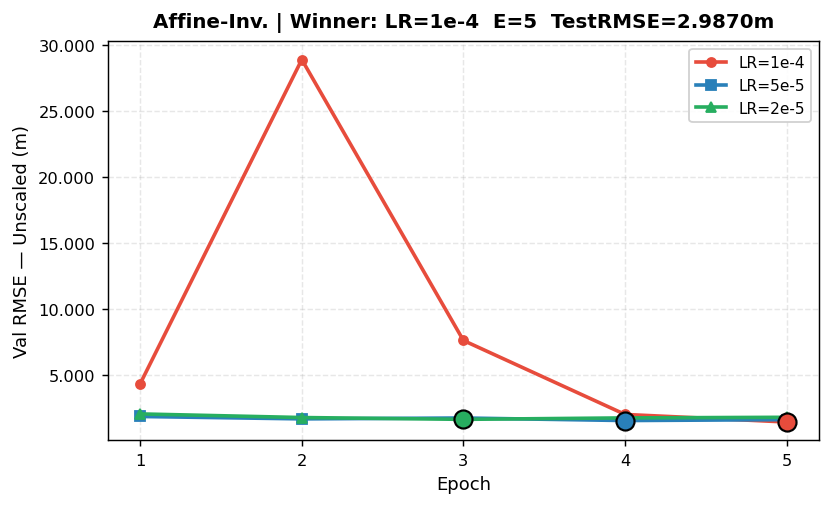

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_epoch_curve_loss_affine_invariant.png


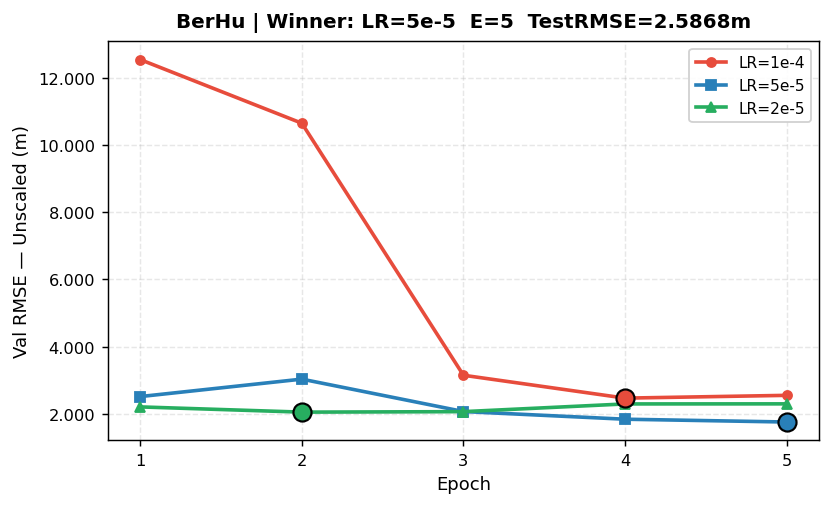

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_epoch_curve_loss_berhu.png


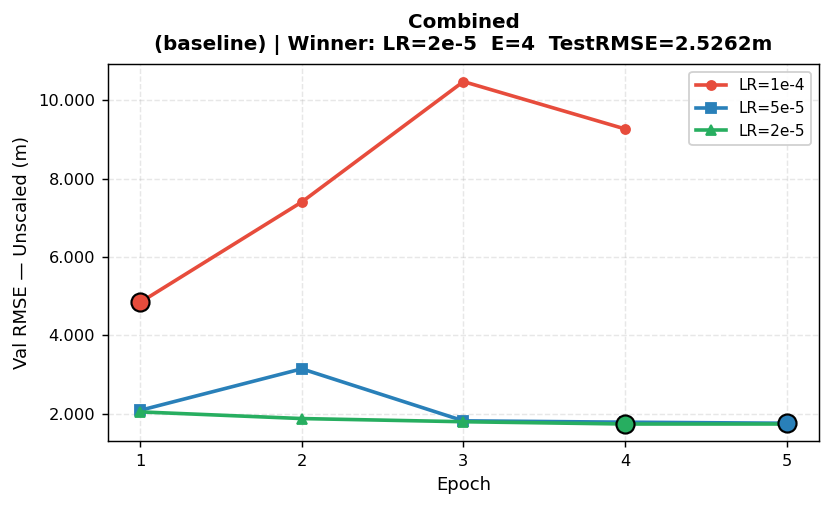

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_epoch_curve_loss_combined_base.png


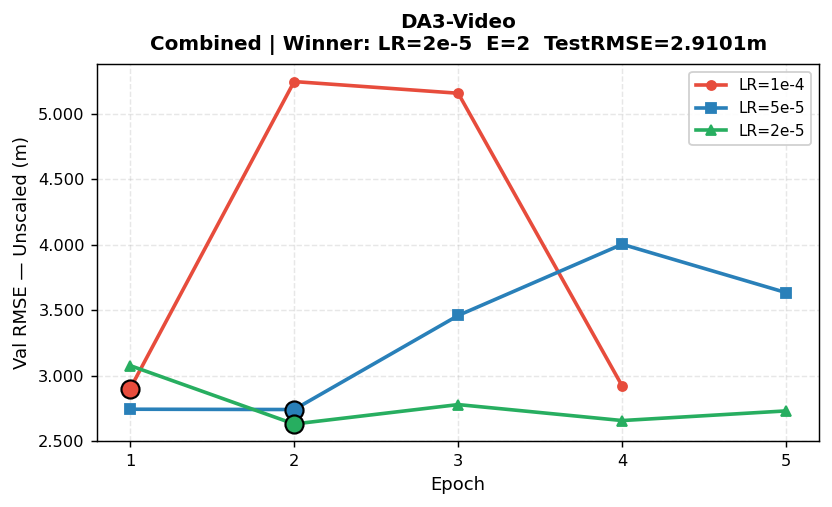

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_epoch_curve_loss_da3_video_combined.png


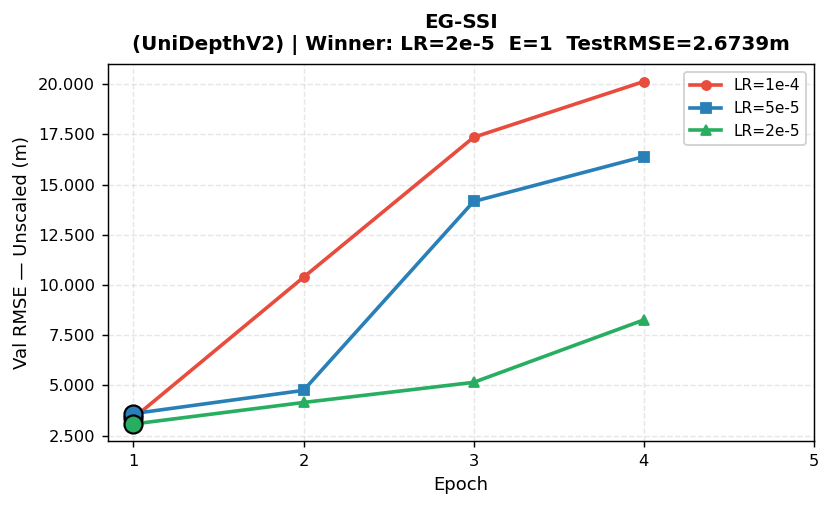

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_epoch_curve_loss_eg_ssi.png


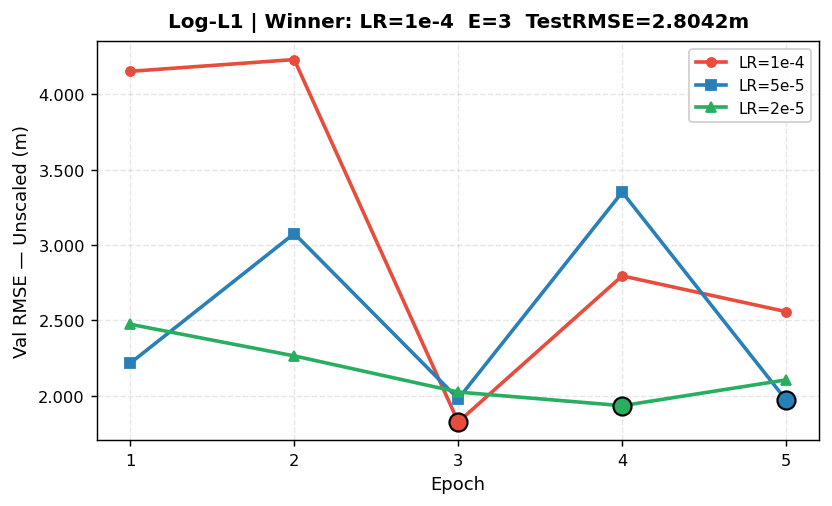

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_epoch_curve_loss_log_l1.png


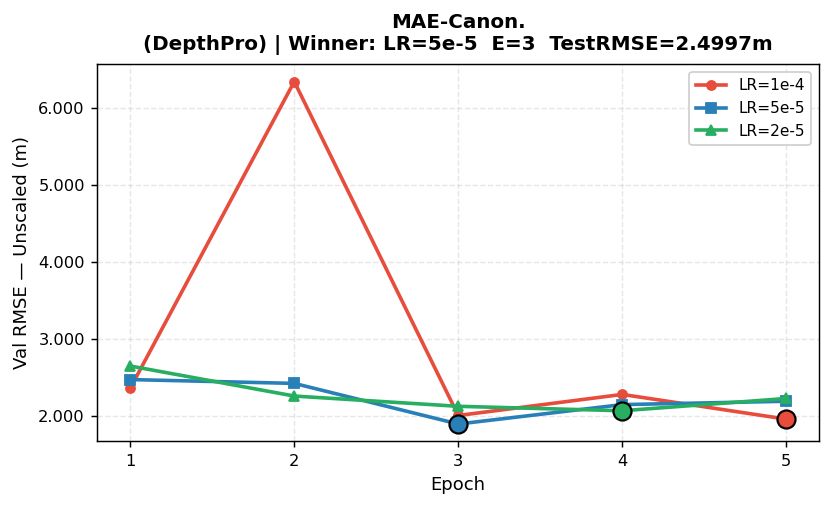

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_epoch_curve_loss_mae_canonical.png


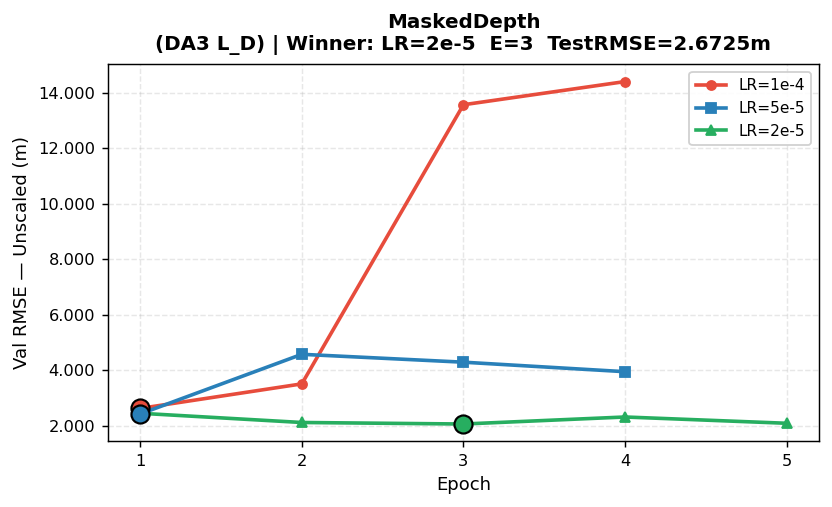

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_epoch_curve_loss_masked_depth.png


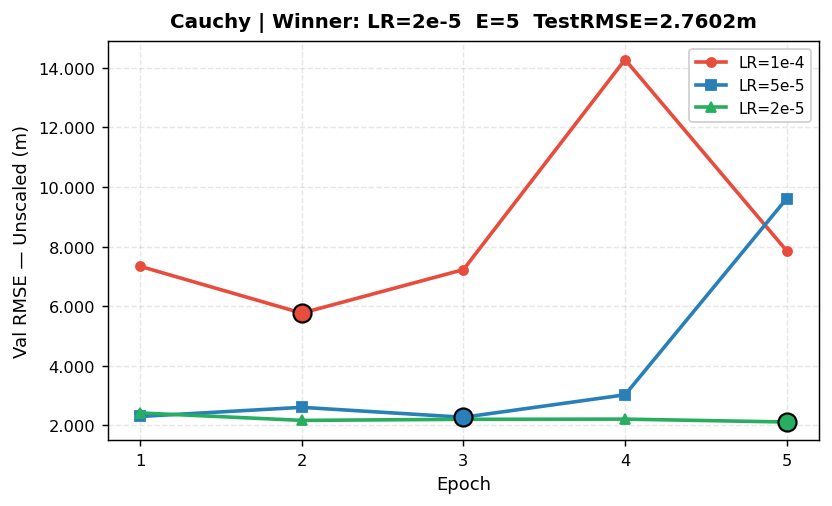

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_epoch_curve_loss_robust_cauchy.png


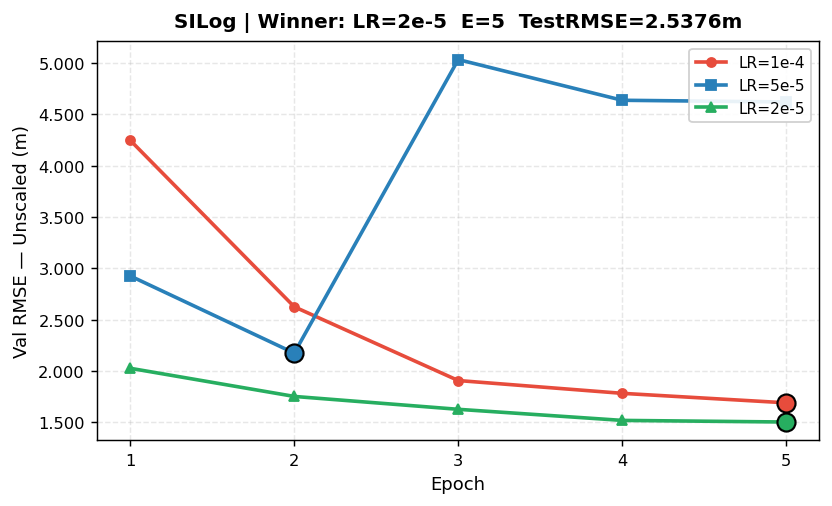

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_epoch_curve_loss_silog.png


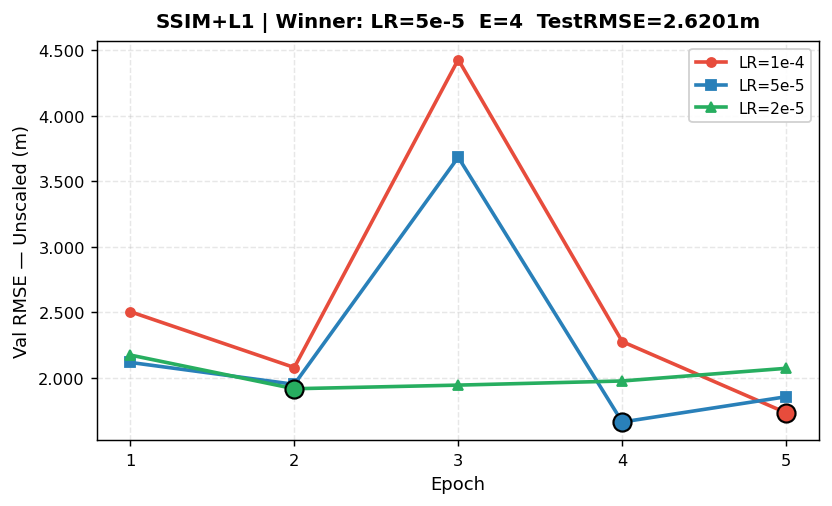

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_epoch_curve_loss_ssim_l1.png


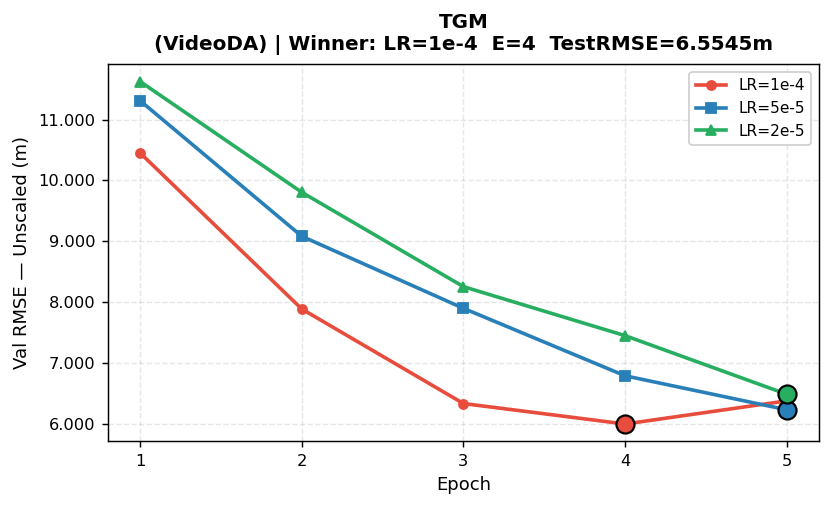

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_epoch_curve_loss_tgm.png


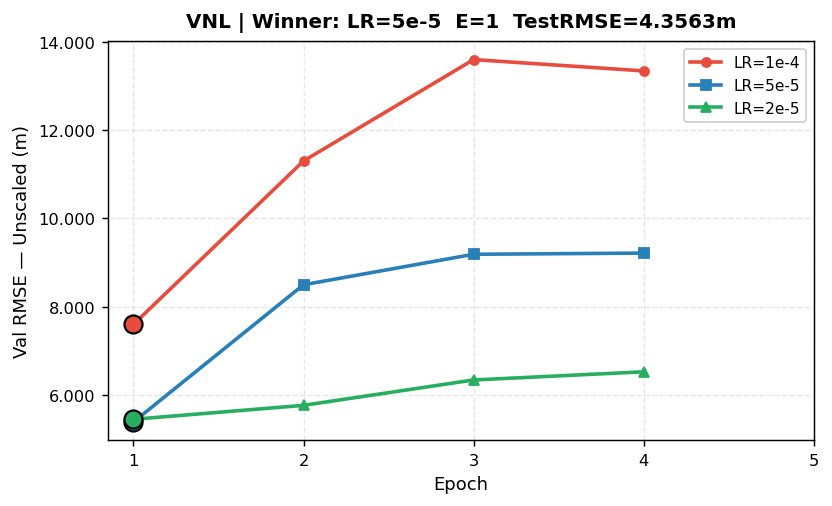

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_epoch_curve_loss_vnl.png


In [5]:
# ── 3.1  Epoch-wise val RMSE — individual figure per loss function (3 LR lines)
plot_epoch_curves_per_config(group_configs['LOSS'], 'LOSS', 'Loss Function')



══════════════════════════════════════════════════════════════════════
  Test RMSE Bar Charts per LR — LOSS FUNCTION
══════════════════════════════════════════════════════════════════════


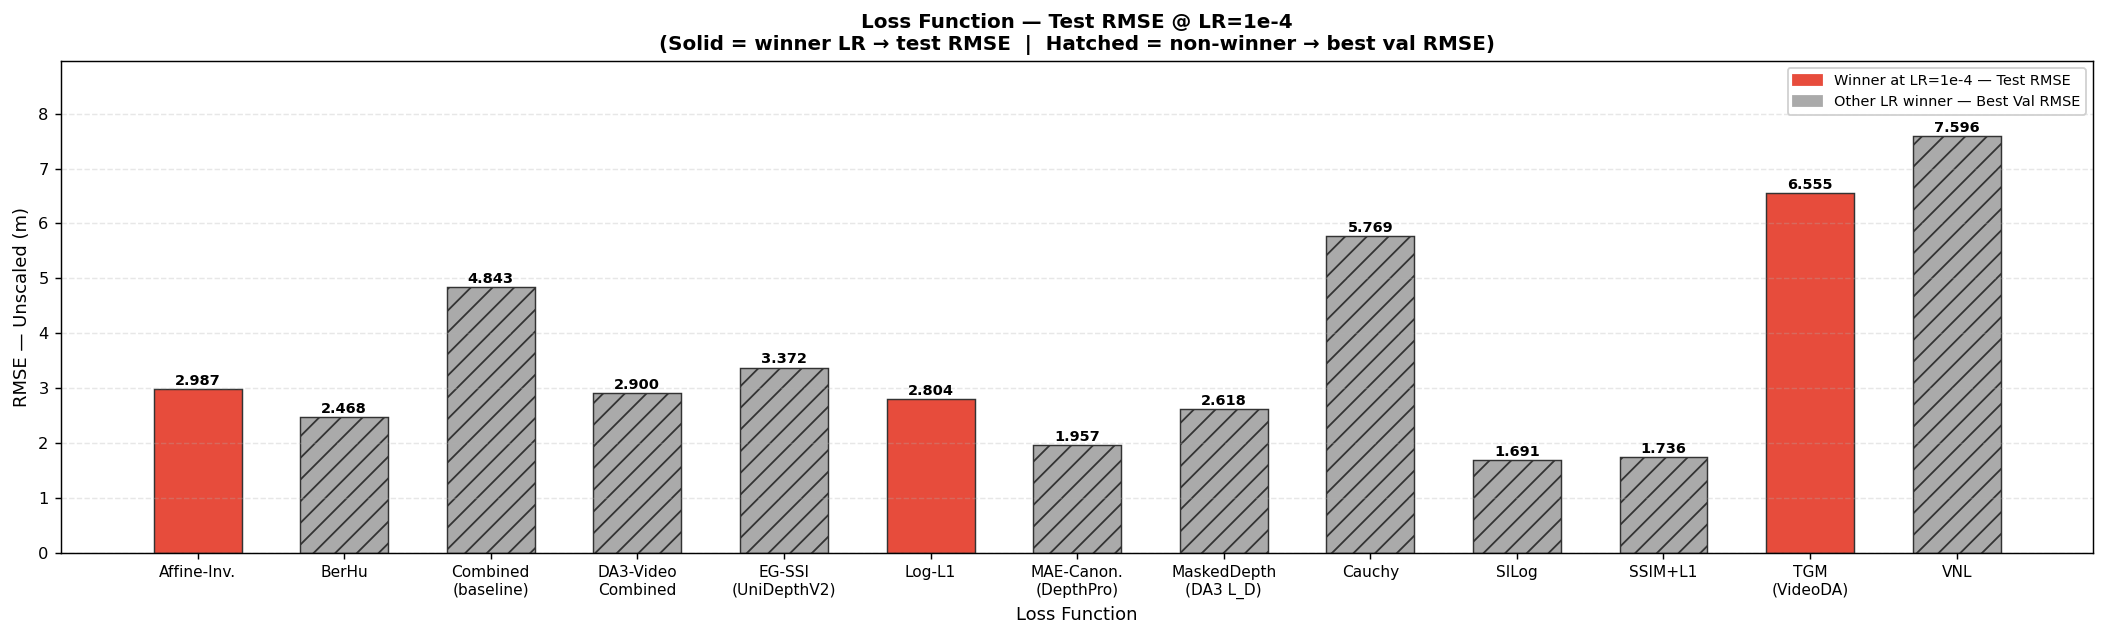

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_bar_test_rmse_lr00001.png


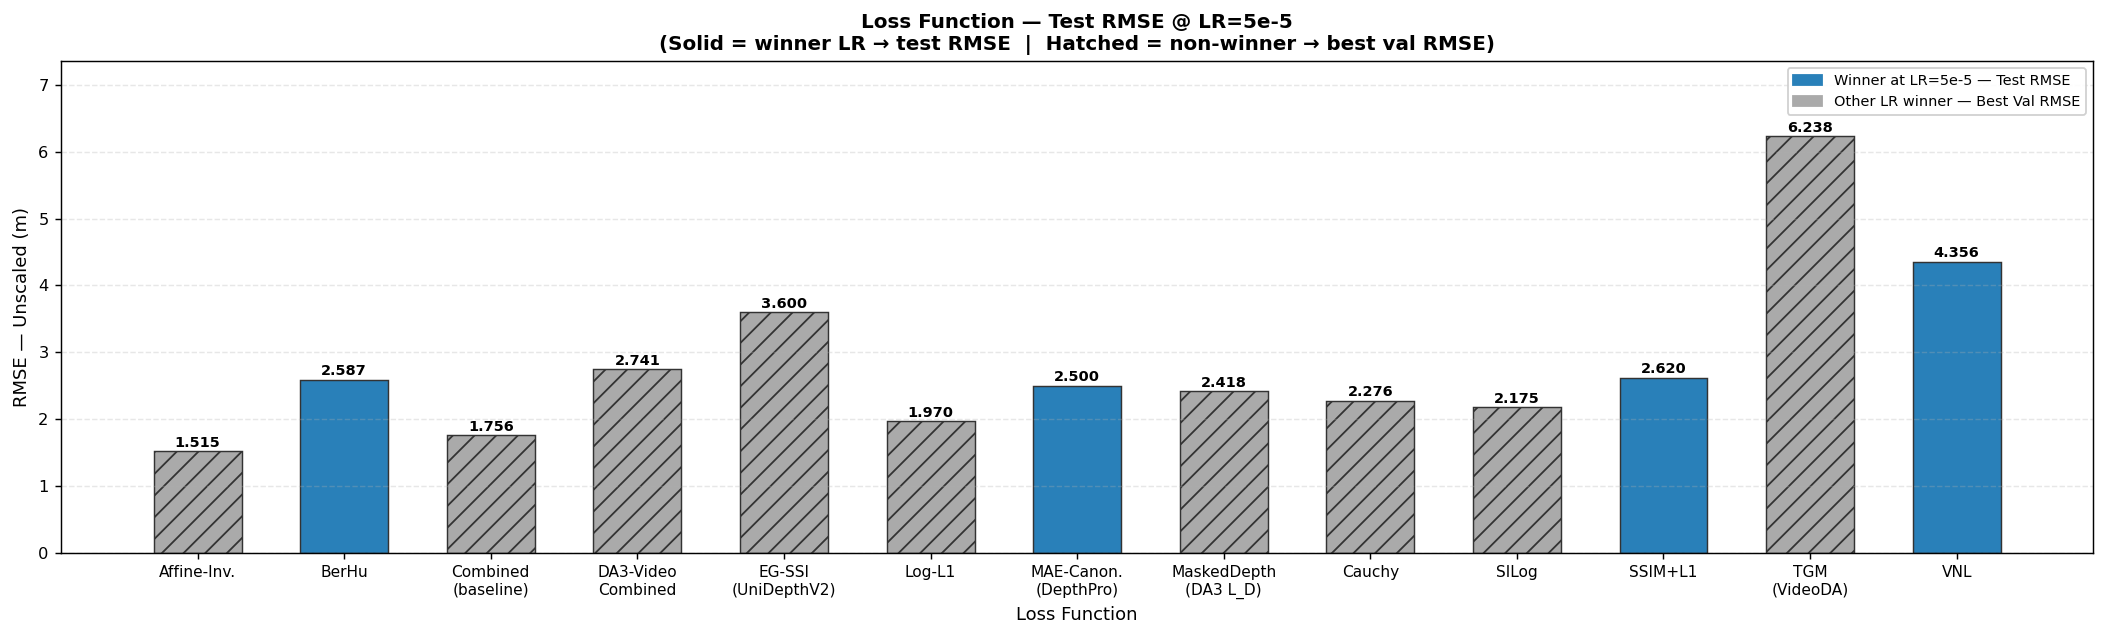

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_bar_test_rmse_lr5e-05.png


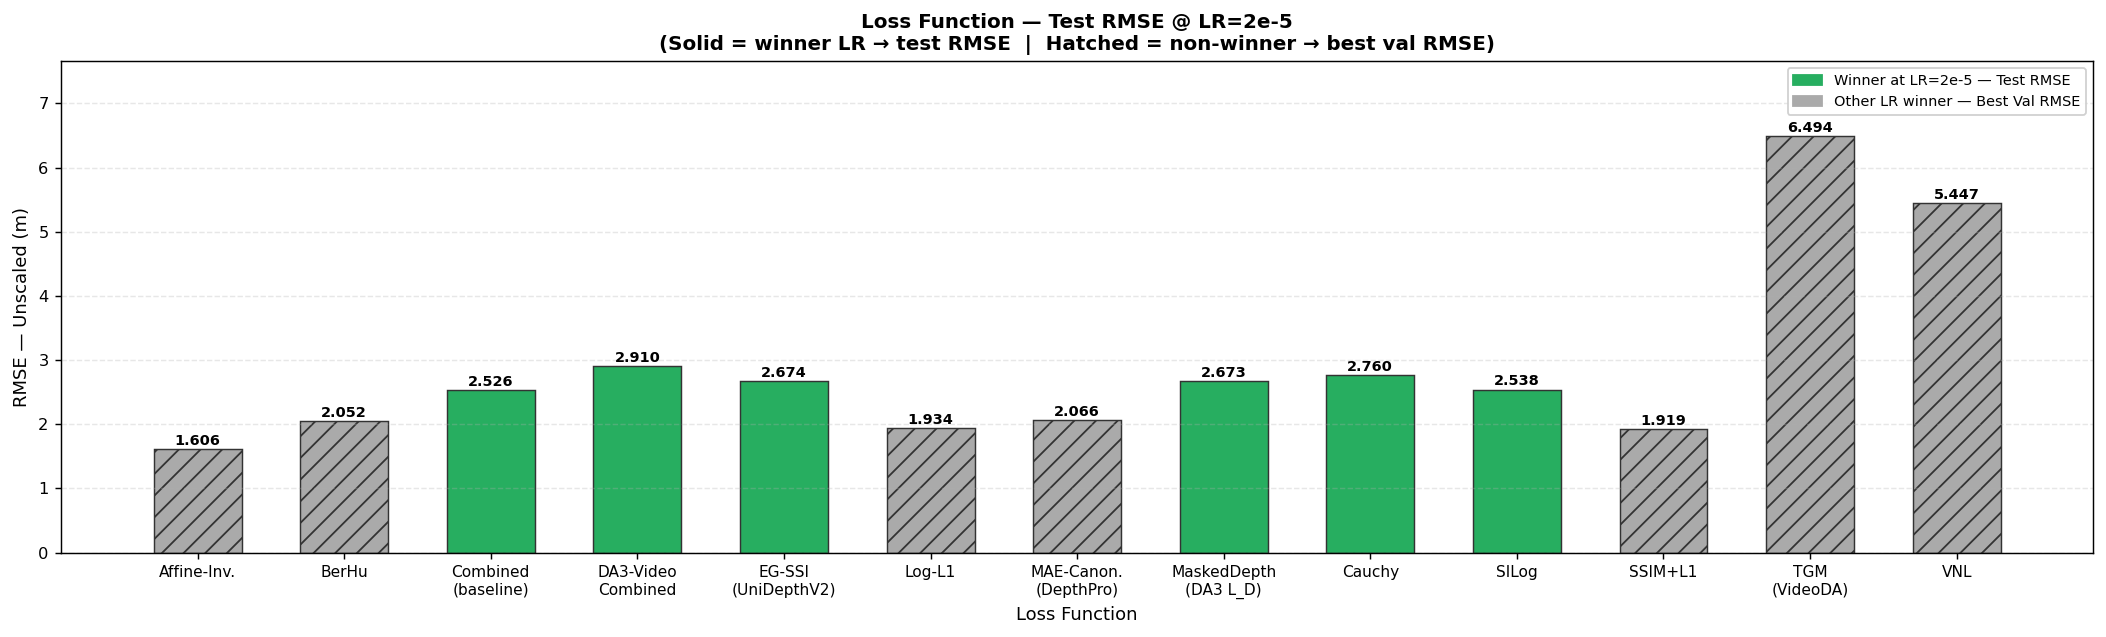

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/loss_bar_test_rmse_lr2e-05.png


In [6]:
# ── 3.2  Bar charts per LR — all loss functions, test RMSE vs val RMSE
plot_bar_charts_per_lr(group_configs['LOSS'], 'LOSS', 'Loss Function')


In [7]:
# ── 3.3  Trajectory quality table
tdf_loss = trajectory_summary_table(group_configs['LOSS'], 'Loss Function')



────────────────────────────────────────────────────────────────────────────────
  Trajectory Quality Analysis — LOSS FUNCTION  (Winner LR)
  (Based on val_rmse epoch history at the winning learning rate)
────────────────────────────────────────────────────────────────────────────────


,Winner LR,Best Val RMSE,Winner Epoch,Improv. Rate,Early Stopped,Trend Slope,Test RMSE,Trajectory
Config,,,,,,,,
loss_affine_invariant,LR=1e-4,1.4042,5/5,75%,No,-3.2691,2.9870,Steady Descent ★
loss_berhu,LR=5e-5,1.7581,5/5,75%,No,-0.2705,2.5868,Steady Descent ★
loss_combined_base,LR=2e-5,1.7365,4/5,75%,No,-0.0759,2.5262,Steady Descent ★
loss_da3_video_combined,LR=2e-5,2.6300,2/5,50%,No,-0.0666,2.9101,Good Convergence
loss_eg_ssi,LR=2e-5,3.0821,1/5,0%,⚠ YES,+1.6548,2.6739,Bouncy / Poor
loss_log_l1,LR=1e-4,1.8256,3/5,50%,No,-0.4623,2.8042,Good Convergence
loss_mae_canonical,LR=5e-5,1.8931,3/5,50%,No,-0.0840,2.4997,Good Convergence
loss_masked_depth,LR=2e-5,2.0557,3/5,75%,No,-0.0524,2.6725,Good Convergence
loss_robust_cauchy,LR=2e-5,2.1163,5/5,50%,No,-0.0566,2.7602,Good Convergence


In [8]:
# ── 3.4  Winner declaration
loss_ranked = declare_winner(group_configs['LOSS'], 'LOSS', 'Loss Function')



════════════════════════════════════════════════════════════════════════════════
  🏆  LOSS FUNCTION RANKING  (by Test RMSE + Trajectory Quality)
════════════════════════════════════════════════════════════════════════════════


,Short Name,Winner LR,Winner Epoch,Best Val RMSE,Test RMSE ↓,AbsRel ↓,δ<1.25 ↑,Trajectory
Rank,,,,,,,,
1,MAE-Canon. (DepthPro),LR=5e-5,3,1.893127,2.499683,0.071948,0.970165,Good Convergence
2,Combined (baseline),LR=2e-5,4,1.736471,2.526200,0.072493,0.967586,Steady Descent ★
3,SILog,LR=2e-5,5,1.503832,2.537587,0.073093,0.964109,Steady Descent ★
4,BerHu,LR=5e-5,5,1.758120,2.586817,0.078651,0.961432,Steady Descent ★
5,SSIM+L1,LR=5e-5,4,1.665622,2.620148,0.078648,0.962019,Good Convergence
6,MaskedDepth (DA3 L_D),LR=2e-5,3,2.055710,2.672515,0.075633,0.962397,Good Convergence
7,EG-SSI (UniDepthV2),LR=2e-5,1,3.082094,2.673856,0.083175,0.968740,Bouncy / Poor
8,Cauchy,LR=2e-5,5,2.116288,2.760158,0.083047,0.963644,Good Convergence
9,Log-L1,LR=1e-4,3,1.825575,2.804235,0.094919,0.948154,Good Convergence



🥇  WINNER: [loss_mae_canonical]
     Short name  : MAE-Canon. (DepthPro)
     Winner LR   : LR=5e-5
     Winner Epoch: 3/5
     Best Val RMSE: 1.8931 m
     Test RMSE   : 2.4997 m  (pixel-weighted unscaled)
     AbsRel      : 0.0719  |  δ<1.25: 0.9702
     Trajectory  : Good Convergence

──────────────────────────────────────────────────  Top-4 Runners-Up  ────────────
  🥈  #2 [loss_combined_base]
        Test RMSE: 2.5262 m  |  LR: LR=2e-5  |  Epoch: 4  |  Traj: Steady Descent ★
  🥉  #3 [loss_silog]
        Test RMSE: 2.5376 m  |  LR: LR=2e-5  |  Epoch: 5  |  Traj: Steady Descent ★
  🏅  #4 [loss_berhu]
        Test RMSE: 2.5868 m  |  LR: LR=5e-5  |  Epoch: 5  |  Traj: Steady Descent ★
  🏅  #5 [loss_ssim_l1]
        Test RMSE: 2.6201 m  |  LR: LR=5e-5  |  Epoch: 4  |  Traj: Good Convergence


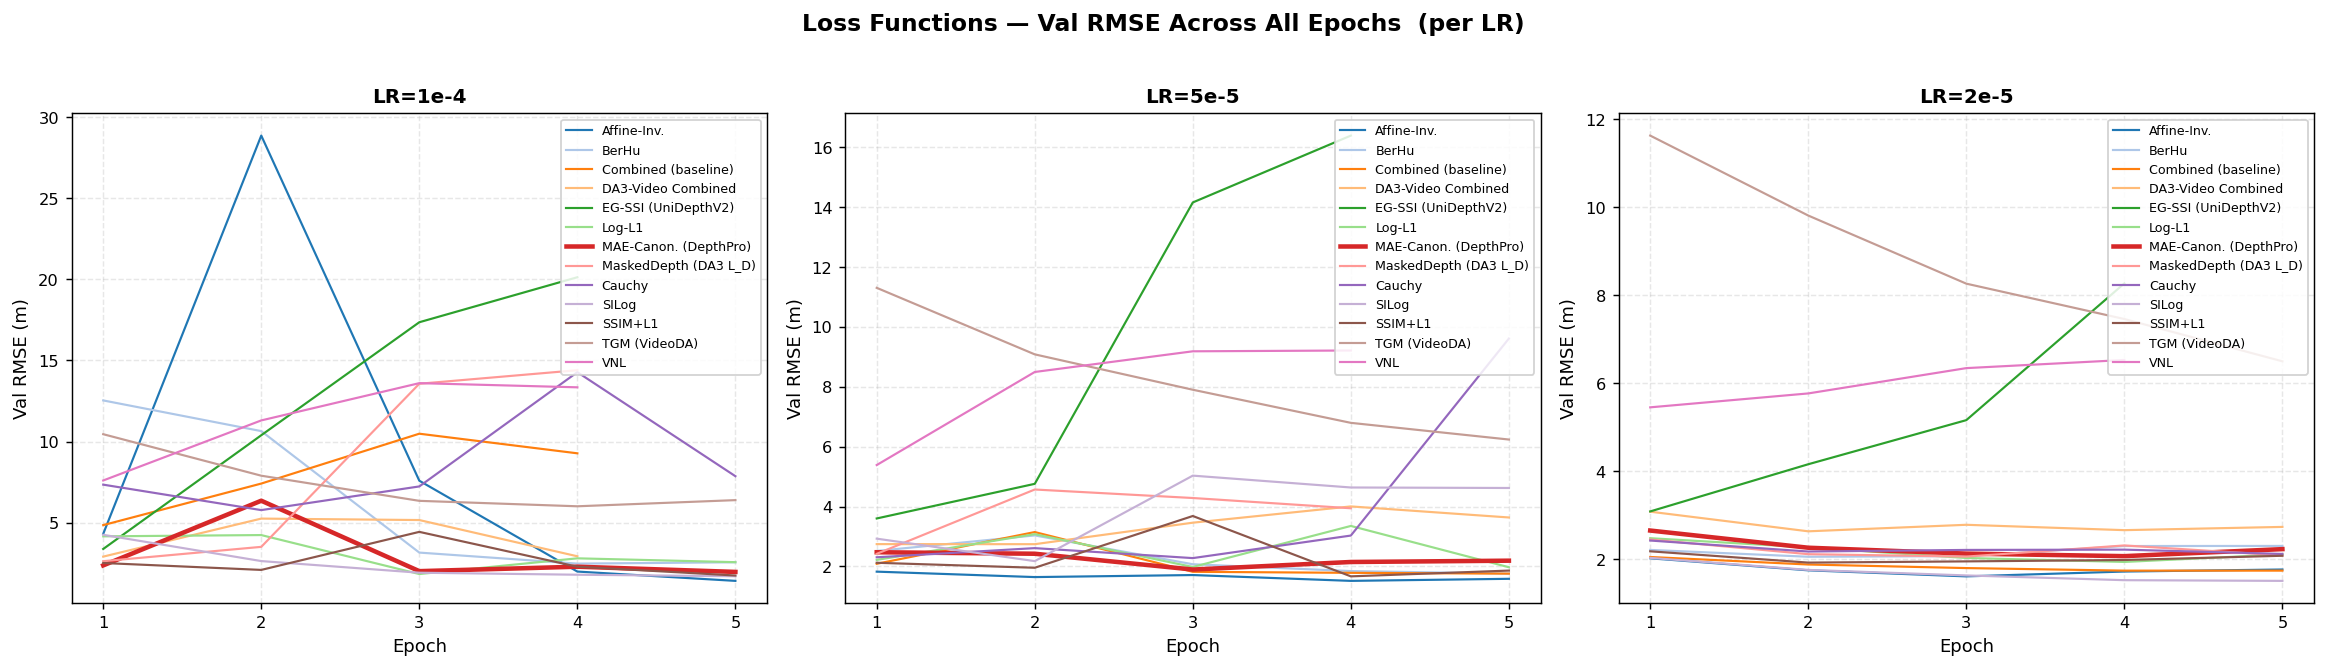

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/LOSS_overview_all_lrs.png


In [9]:
# ── 3.5  Combined overview: val RMSE comparison plot (all LRs, all loss fns together)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
fig.patch.set_facecolor('white')
fig.suptitle("Loss Functions — Val RMSE Across All Epochs  (per LR)", 
             fontsize=13, fontweight='bold', y=1.02)

configs = group_configs['LOSS']
color_map = dict(zip(configs, sns.color_palette("tab20", len(configs))))

for ax, lr_tag in zip(axes, LR_TAGS):
    for cfg in configs:
        df = get_config_history(cfg, lr_tag)
        if df.empty or 'val_rmse' not in df.columns:
            continue
        lw = 2.5 if cfg == loss_ranked.iloc[0]['Config'] else 1.2
        ax.plot(df['epoch'], df['val_rmse'],
                color=color_map[cfg], linewidth=lw,
                label=sname(cfg).replace('\n',' '))
    ax.set_title(LR_DISPLAY[lr_tag], fontweight='bold')
    ax.set_xlabel("Epoch"); ax.set_ylabel("Val RMSE (m)")
    ax.set_xticks(range(1, ABLATION_EPOCHS+1))
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.legend(loc='upper right', fontsize=7, ncol=1, framealpha=0.85)

plt.tight_layout()
save_and_show(fig, "LOSS_overview_all_lrs.png")


---
## 4 · Group 2: Architecture Ablation
> 3 variants: `decoder_only`, `last2_blocks`, `full`.  Fixed: `loss=combined_base`, `aug=base`, `optim=adamw+cosine_warmup`


══════════════════════════════════════════════════════════════════════
  Epoch-Wise Val RMSE Curves — ARCHITECTURE
══════════════════════════════════════════════════════════════════════


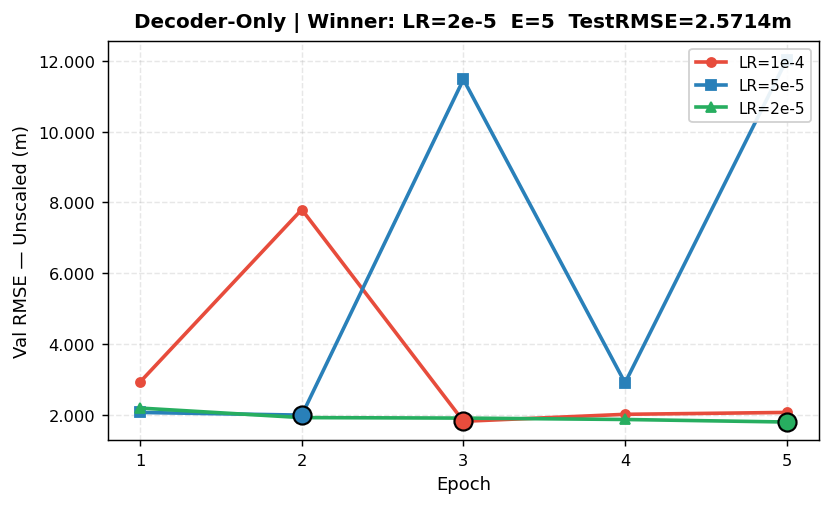

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/arch_epoch_curve_arch_decoder_only.png


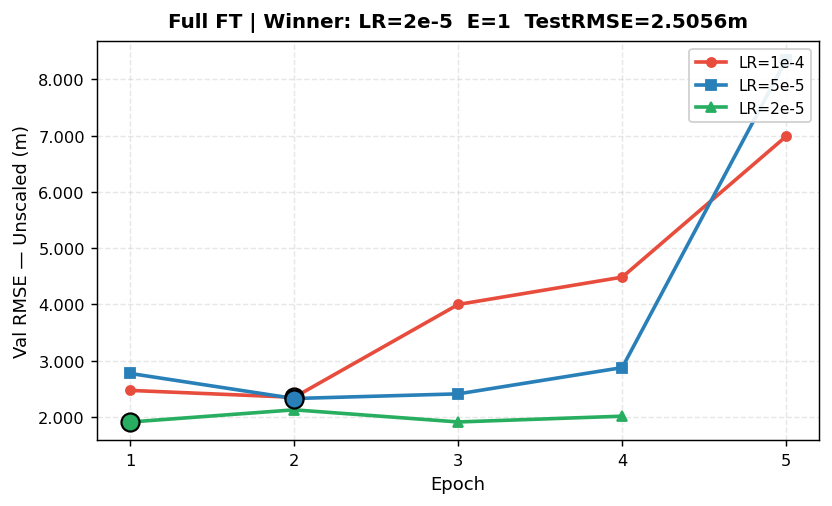

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/arch_epoch_curve_arch_full.png


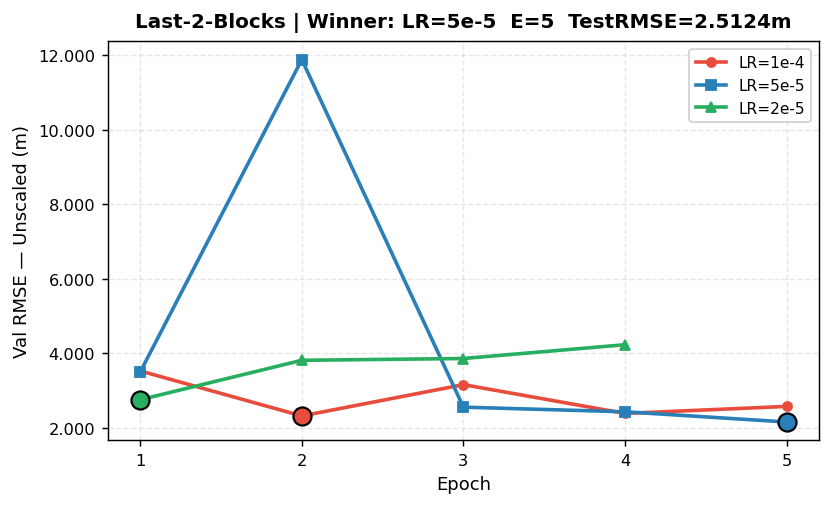

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/arch_epoch_curve_arch_last2_blocks.png


In [10]:
# ── 4.1  Epoch-wise val RMSE — individual figure per arch variant
plot_epoch_curves_per_config(group_configs['ARCH'], 'ARCH', 'Architecture')



══════════════════════════════════════════════════════════════════════
  Test RMSE Bar Charts per LR — ARCHITECTURE
══════════════════════════════════════════════════════════════════════


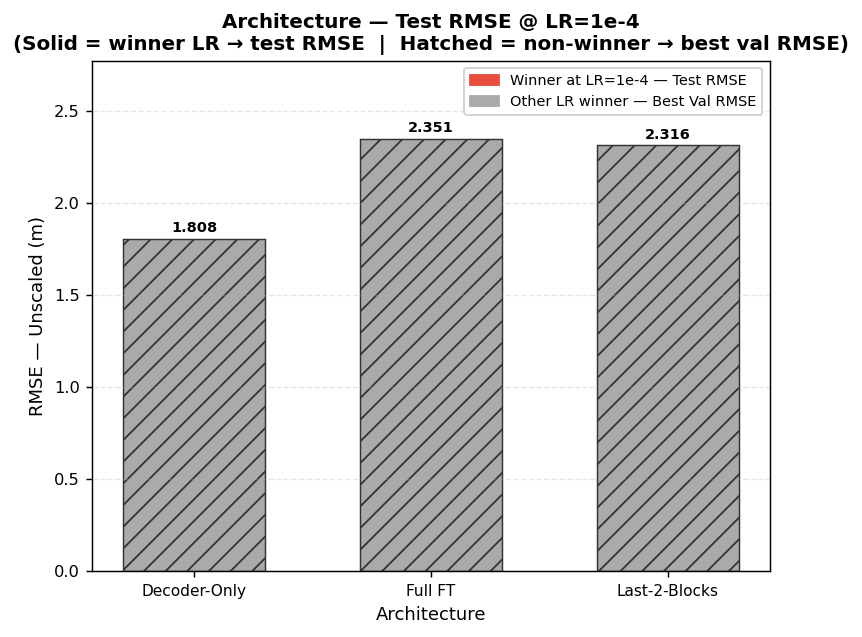

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/arch_bar_test_rmse_lr00001.png


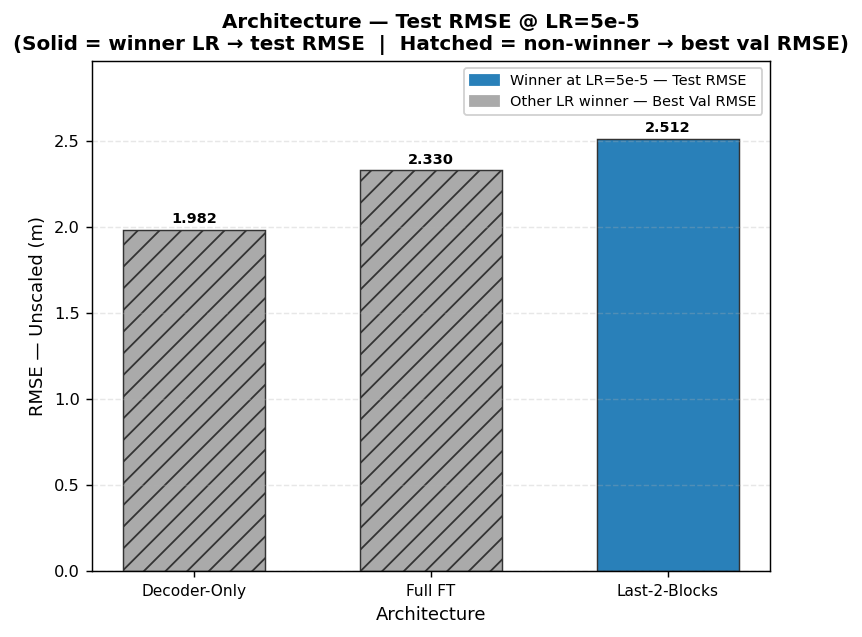

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/arch_bar_test_rmse_lr5e-05.png


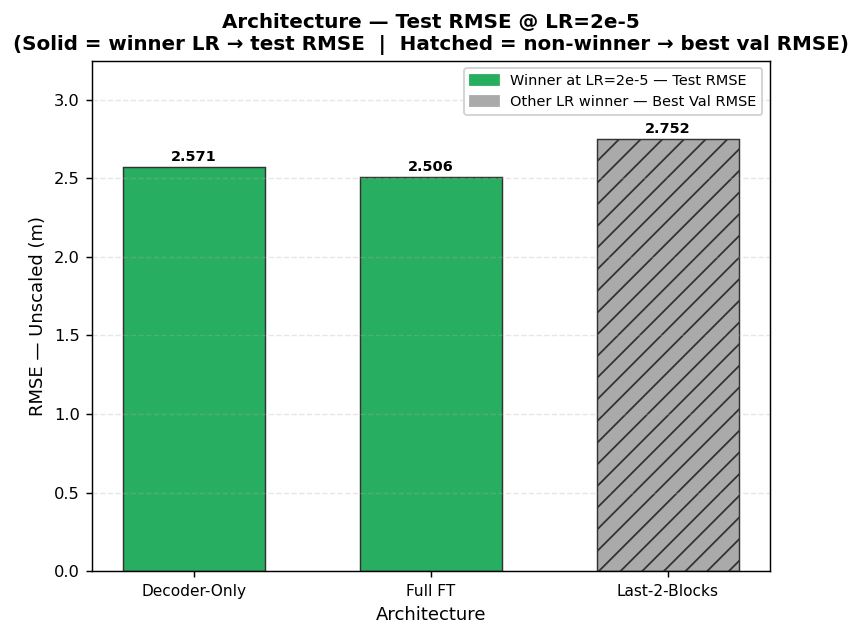

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/arch_bar_test_rmse_lr2e-05.png


In [11]:
# ── 4.2  Bar charts per LR
plot_bar_charts_per_lr(group_configs['ARCH'], 'ARCH', 'Architecture')


In [12]:
# ── 4.3  Trajectory quality table
tdf_arch = trajectory_summary_table(group_configs['ARCH'], 'Architecture')



────────────────────────────────────────────────────────────────────────────────
  Trajectory Quality Analysis — ARCHITECTURE  (Winner LR)
  (Based on val_rmse epoch history at the winning learning rate)
────────────────────────────────────────────────────────────────────────────────


,Winner LR,Best Val RMSE,Winner Epoch,Improv. Rate,Early Stopped,Trend Slope,Test RMSE,Trajectory
Config,,,,,,,,
arch_decoder_only,LR=2e-5,1.7875,5/5,100%,No,-0.0842,2.5714,Steady Descent ★
arch_full,LR=2e-5,1.9121,1/5,33%,⚠ YES,+0.0095,2.5056,Bouncy / Poor
arch_last2_blocks,LR=5e-5,2.1530,5/5,75%,No,-1.2137,2.5124,Steady Descent ★


In [13]:
# ── 4.4  Winner declaration
arch_ranked = declare_winner(group_configs['ARCH'], 'ARCH', 'Architecture')



════════════════════════════════════════════════════════════════════════════════
  🏆  ARCHITECTURE RANKING  (by Test RMSE + Trajectory Quality)
════════════════════════════════════════════════════════════════════════════════


,Short Name,Winner LR,Winner Epoch,Best Val RMSE,Test RMSE ↓,AbsRel ↓,δ<1.25 ↑,Trajectory
Rank,,,,,,,,
1,Last-2-Blocks,LR=5e-5,5,2.153049,2.512423,0.079300,0.966048,Steady Descent ★
2,Decoder-Only,LR=2e-5,5,1.787490,2.571352,0.071793,0.968999,Steady Descent ★
3,Full FT,LR=2e-5,1,1.912099,2.505597,0.071311,0.966158,Bouncy / Poor



🥇  WINNER: [arch_last2_blocks]
     Short name  : Last-2-Blocks
     Winner LR   : LR=5e-5
     Winner Epoch: 5/5
     Best Val RMSE: 2.1530 m
     Test RMSE   : 2.5124 m  (pixel-weighted unscaled)
     AbsRel      : 0.0793  |  δ<1.25: 0.9660
     Trajectory  : Steady Descent ★

──────────────────────────────────────────────────  Top-4 Runners-Up  ────────────
  🥈  #2 [arch_decoder_only]
        Test RMSE: 2.5714 m  |  LR: LR=2e-5  |  Epoch: 5  |  Traj: Steady Descent ★
  🥉  #3 [arch_full]
        Test RMSE: 2.5056 m  |  LR: LR=2e-5  |  Epoch: 1  |  Traj: Bouncy / Poor


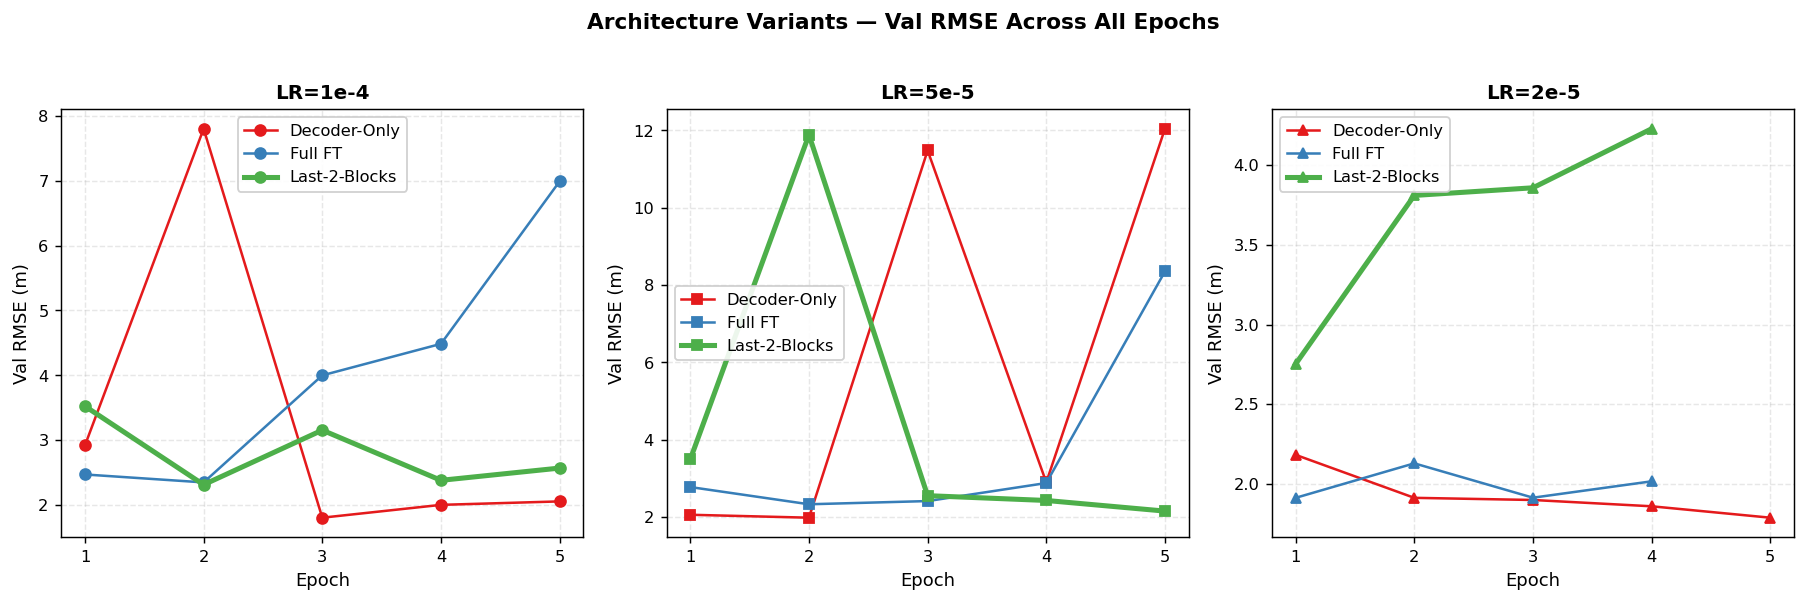

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/ARCH_overview_all_lrs.png


In [14]:
# ── 4.5  Overview comparison
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=False)
fig.patch.set_facecolor('white')
fig.suptitle("Architecture Variants — Val RMSE Across All Epochs", 
             fontsize=12, fontweight='bold', y=1.02)

configs = group_configs['ARCH']
color_map = dict(zip(configs, sns.color_palette("Set1", len(configs))))

for ax, lr_tag in zip(axes, LR_TAGS):
    for cfg in configs:
        df = get_config_history(cfg, lr_tag)
        if df.empty or 'val_rmse' not in df.columns:
            continue
        lw = 2.8 if cfg == arch_ranked.iloc[0]['Config'] else 1.4
        ax.plot(df['epoch'], df['val_rmse'],
                color=color_map[cfg], linewidth=lw,
                marker=LR_MARKERS[lr_tag], markersize=6,
                label=sname(cfg))
    ax.set_title(LR_DISPLAY[lr_tag], fontweight='bold')
    ax.set_xlabel("Epoch"); ax.set_ylabel("Val RMSE (m)")
    ax.set_xticks(range(1, ABLATION_EPOCHS+1))
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.legend(fontsize=9, framealpha=0.9)

plt.tight_layout()
save_and_show(fig, "ARCH_overview_all_lrs.png")


---
## 5 · Group 3: Augmentation Ablation
> 4 variants: `none`, `flip`, `base` (flip+jitter), `full` (flip+jitter+crop).  Fixed: `loss=combined_base`, `arch=decoder_only`, `optim=adamw+cosine_warmup`


══════════════════════════════════════════════════════════════════════
  Epoch-Wise Val RMSE Curves — AUGMENTATION
══════════════════════════════════════════════════════════════════════


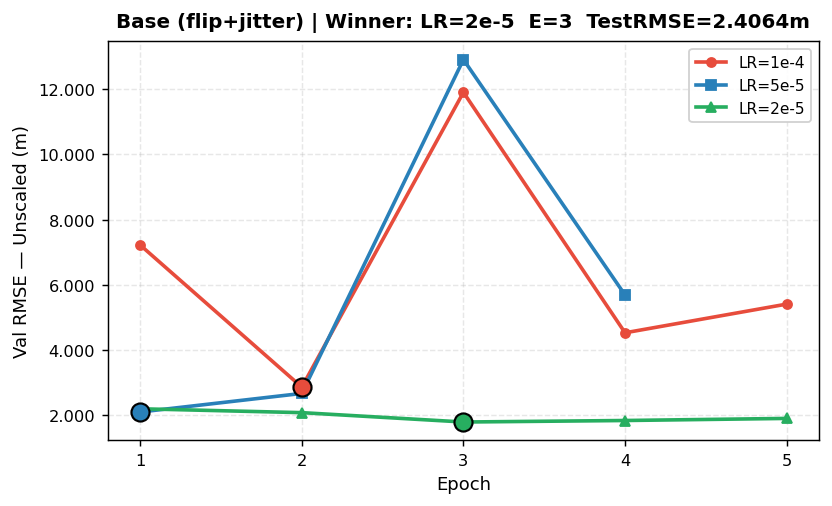

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/aug_epoch_curve_aug_base.png


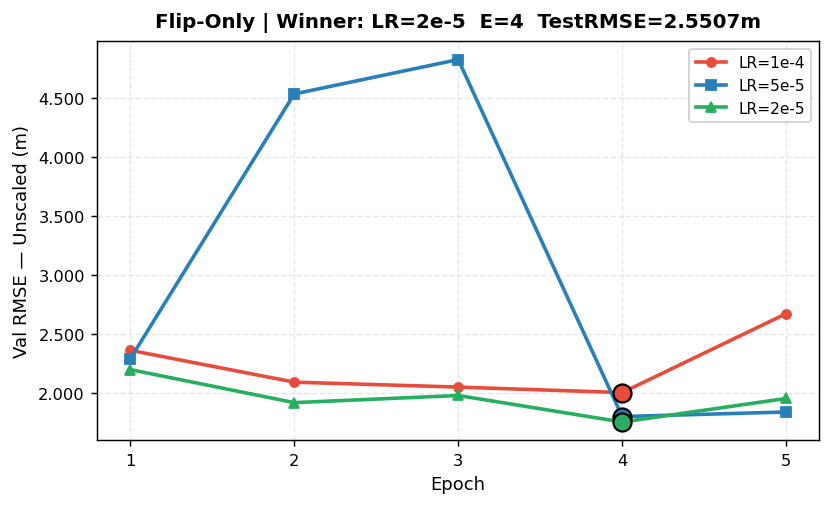

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/aug_epoch_curve_aug_flip.png


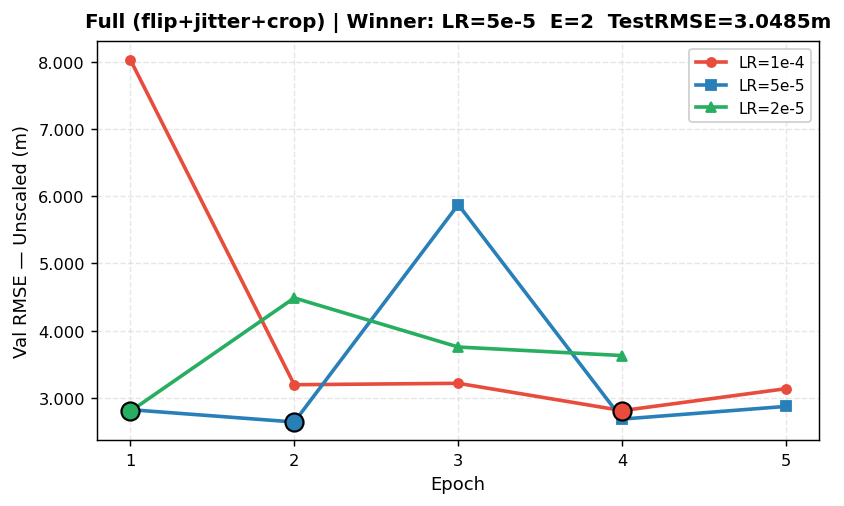

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/aug_epoch_curve_aug_full.png


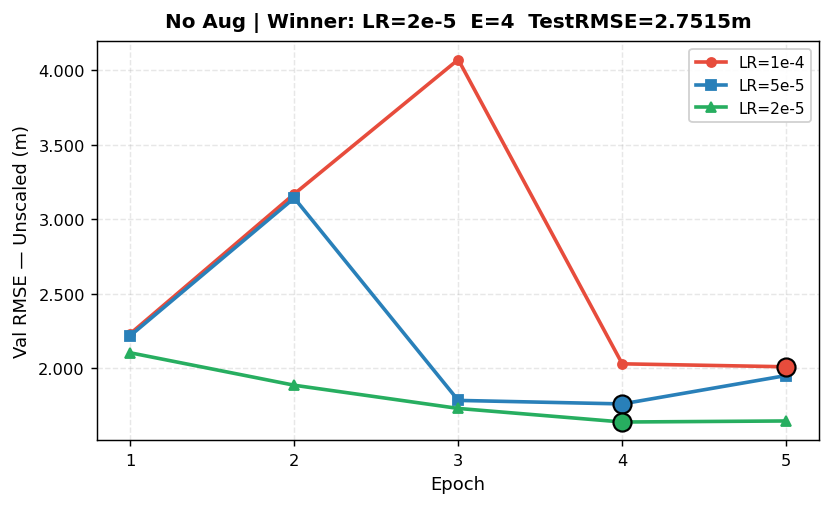

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/aug_epoch_curve_aug_none.png


In [15]:
# ── 5.1  Epoch-wise val RMSE — individual figure per aug variant
plot_epoch_curves_per_config(group_configs['AUG'], 'AUG', 'Augmentation')



══════════════════════════════════════════════════════════════════════
  Test RMSE Bar Charts per LR — AUGMENTATION
══════════════════════════════════════════════════════════════════════


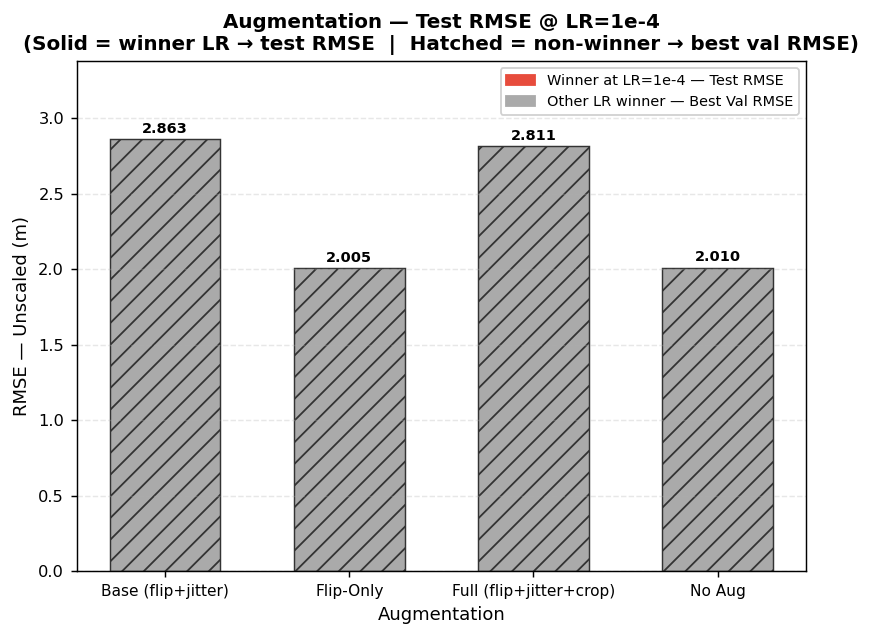

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/aug_bar_test_rmse_lr00001.png


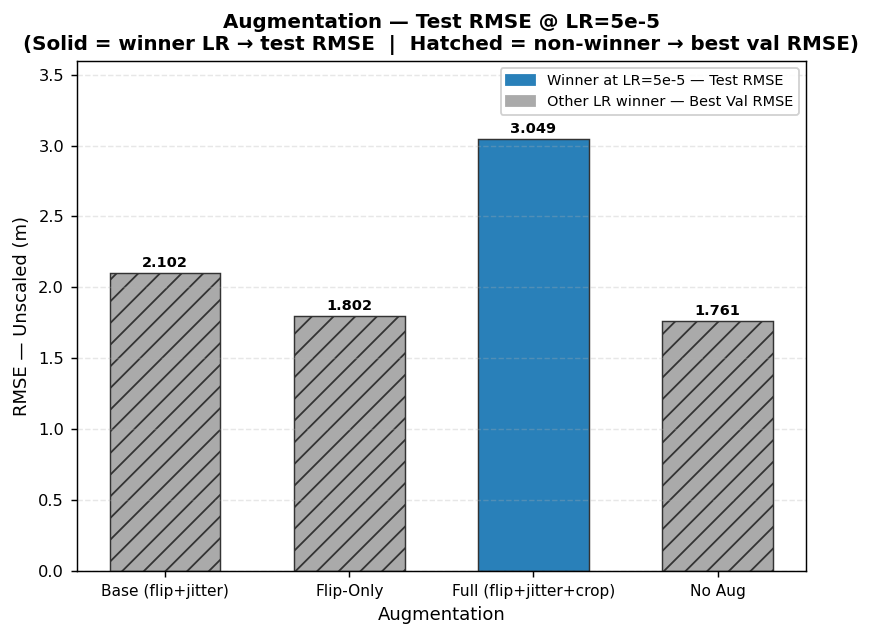

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/aug_bar_test_rmse_lr5e-05.png


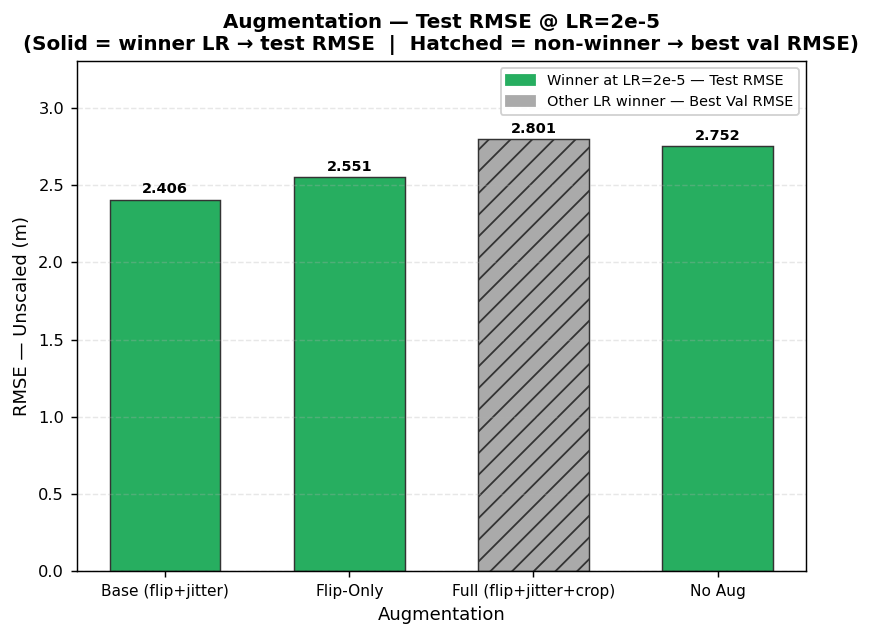

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/aug_bar_test_rmse_lr2e-05.png


In [16]:
# ── 5.2  Bar charts per LR
plot_bar_charts_per_lr(group_configs['AUG'], 'AUG', 'Augmentation')


In [17]:
# ── 5.3  Trajectory quality table
tdf_aug = trajectory_summary_table(group_configs['AUG'], 'Augmentation')



────────────────────────────────────────────────────────────────────────────────
  Trajectory Quality Analysis — AUGMENTATION  (Winner LR)
  (Based on val_rmse epoch history at the winning learning rate)
────────────────────────────────────────────────────────────────────────────────


,Winner LR,Best Val RMSE,Winner Epoch,Improv. Rate,Early Stopped,Trend Slope,Test RMSE,Trajectory
Config,,,,,,,,
aug_base,LR=2e-5,1.7951,3/5,50%,No,-0.0831,2.4064,Good Convergence
aug_flip,LR=2e-5,1.7555,4/5,50%,No,-0.0653,2.5507,Good Convergence
aug_full,LR=5e-5,2.6419,2/5,50%,No,+0.0142,3.0485,Good Convergence
aug_none,LR=2e-5,1.6396,4/5,75%,No,-0.1161,2.7515,Steady Descent ★


In [18]:
# ── 5.4  Winner declaration
aug_ranked = declare_winner(group_configs['AUG'], 'AUG', 'Augmentation')



════════════════════════════════════════════════════════════════════════════════
  🏆  AUGMENTATION RANKING  (by Test RMSE + Trajectory Quality)
════════════════════════════════════════════════════════════════════════════════


,Short Name,Winner LR,Winner Epoch,Best Val RMSE,Test RMSE ↓,AbsRel ↓,δ<1.25 ↑,Trajectory
Rank,,,,,,,,
1,Base (flip+jitter),LR=2e-5,3,1.795098,2.406417,0.074260,0.968918,Good Convergence
2,Flip-Only,LR=2e-5,4,1.755545,2.550666,0.074111,0.966674,Good Convergence
3,No Aug,LR=2e-5,4,1.639606,2.751501,0.083474,0.950837,Steady Descent ★
4,Full (flip+jitter+crop),LR=5e-5,2,2.641883,3.048536,0.122965,0.934423,Good Convergence



🥇  WINNER: [aug_base]
     Short name  : Base (flip+jitter)
     Winner LR   : LR=2e-5
     Winner Epoch: 3/5
     Best Val RMSE: 1.7951 m
     Test RMSE   : 2.4064 m  (pixel-weighted unscaled)
     AbsRel      : 0.0743  |  δ<1.25: 0.9689
     Trajectory  : Good Convergence

──────────────────────────────────────────────────  Top-4 Runners-Up  ────────────
  🥈  #2 [aug_flip]
        Test RMSE: 2.5507 m  |  LR: LR=2e-5  |  Epoch: 4  |  Traj: Good Convergence
  🥉  #3 [aug_none]
        Test RMSE: 2.7515 m  |  LR: LR=2e-5  |  Epoch: 4  |  Traj: Steady Descent ★
  🏅  #4 [aug_full]
        Test RMSE: 3.0485 m  |  LR: LR=5e-5  |  Epoch: 2  |  Traj: Good Convergence


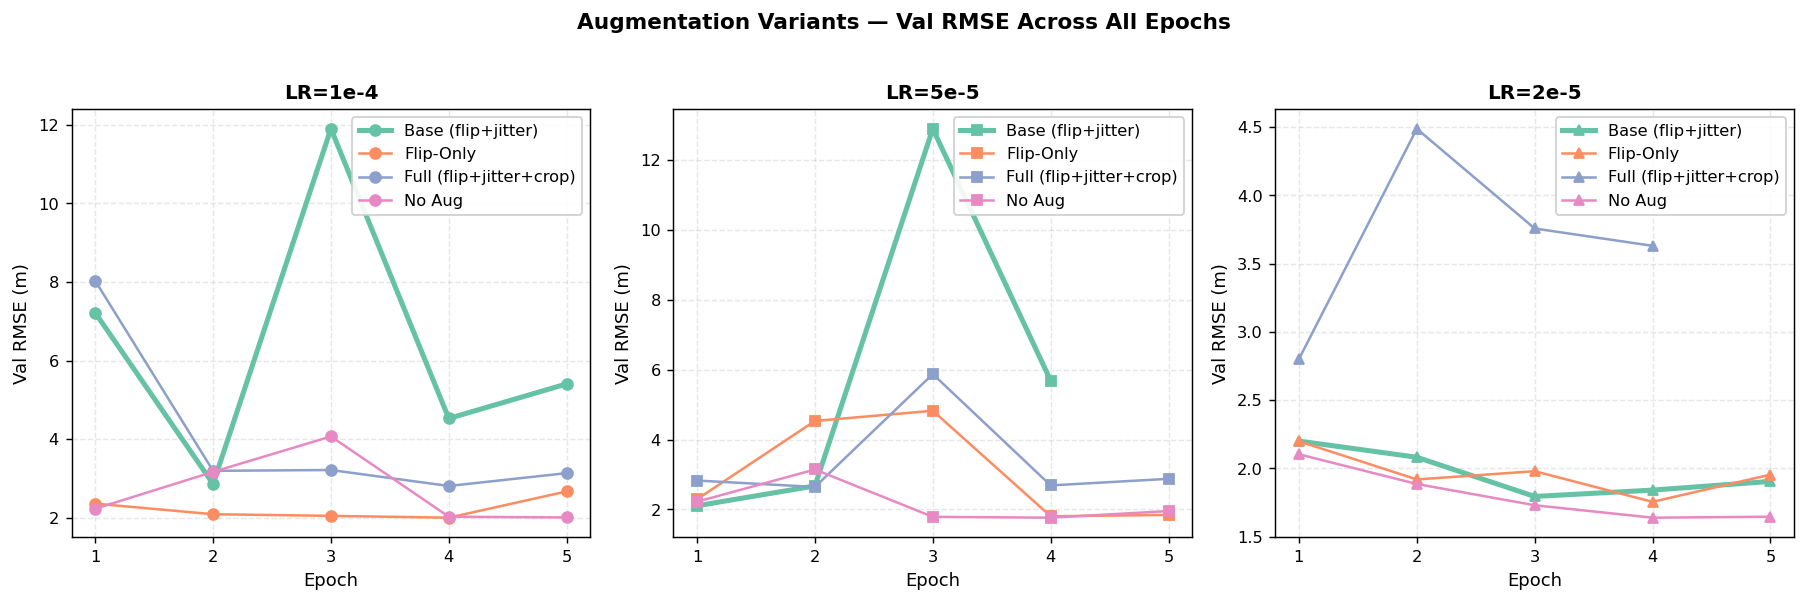

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/AUG_overview_all_lrs.png


In [19]:
# ── 5.5  Overview comparison
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=False)
fig.patch.set_facecolor('white')
fig.suptitle("Augmentation Variants — Val RMSE Across All Epochs", 
             fontsize=12, fontweight='bold', y=1.02)

configs = group_configs['AUG']
color_map = dict(zip(configs, sns.color_palette("Set2", len(configs))))

for ax, lr_tag in zip(axes, LR_TAGS):
    for cfg in configs:
        df = get_config_history(cfg, lr_tag)
        if df.empty or 'val_rmse' not in df.columns:
            continue
        lw = 2.8 if cfg == aug_ranked.iloc[0]['Config'] else 1.4
        ax.plot(df['epoch'], df['val_rmse'],
                color=color_map[cfg], linewidth=lw,
                marker=LR_MARKERS[lr_tag], markersize=6,
                label=sname(cfg).replace('\n',' '))
    ax.set_title(LR_DISPLAY[lr_tag], fontweight='bold')
    ax.set_xlabel("Epoch"); ax.set_ylabel("Val RMSE (m)")
    ax.set_xticks(range(1, ABLATION_EPOCHS+1))
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.legend(fontsize=9, framealpha=0.9)

plt.tight_layout()
save_and_show(fig, "AUG_overview_all_lrs.png")


---
## 6 · Group 4: Optimizer / Scheduler Ablation
> 5 variants: `adamw+cosine_warmup`, `adam+cosine_warmup`, `sgd+cosine_warmup`, `adamw+onecycle`, `adamw+step`.  Fixed: `loss=combined_base`, `arch=decoder_only`, `aug=base`


══════════════════════════════════════════════════════════════════════
  Epoch-Wise Val RMSE Curves — OPTIMIZER/SCHEDULER
══════════════════════════════════════════════════════════════════════


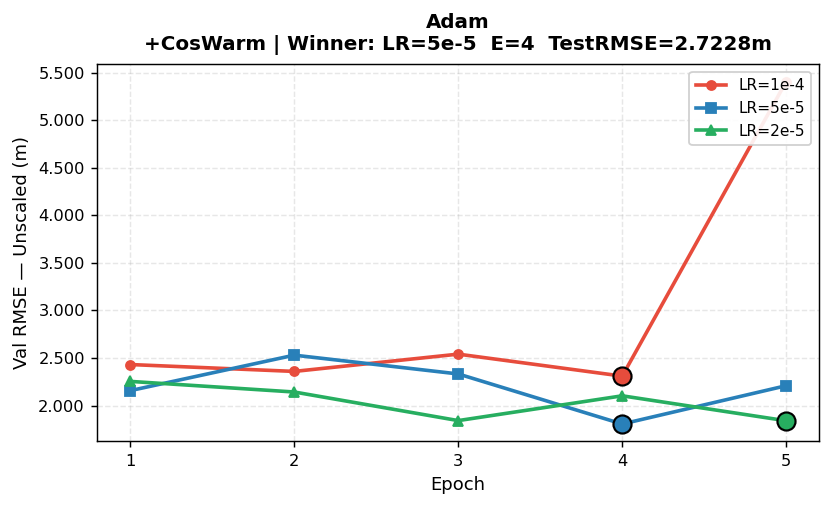

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/optim_epoch_curve_optim_adam_cosine_warmup.png


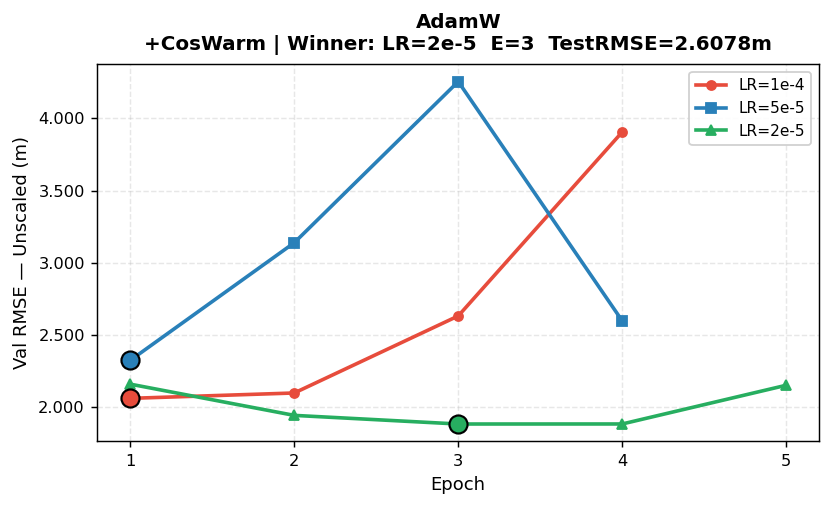

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/optim_epoch_curve_optim_adamw_cosine_warmup.png


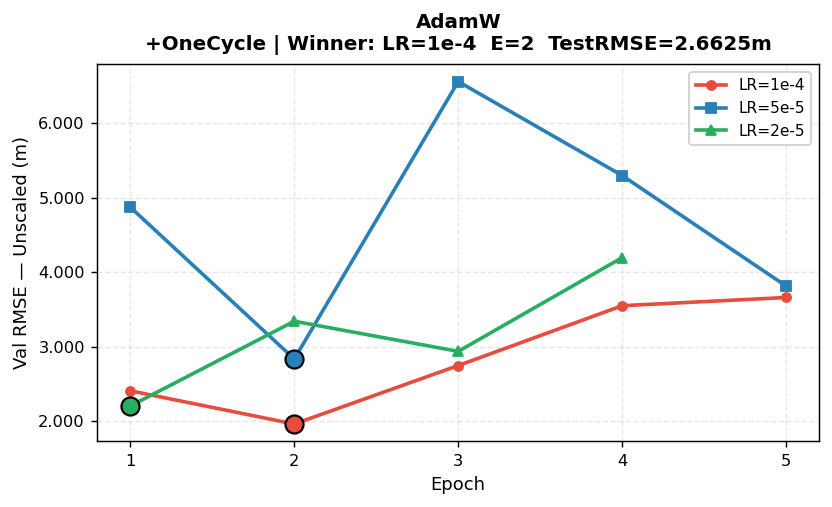

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/optim_epoch_curve_optim_adamw_onecycle.png


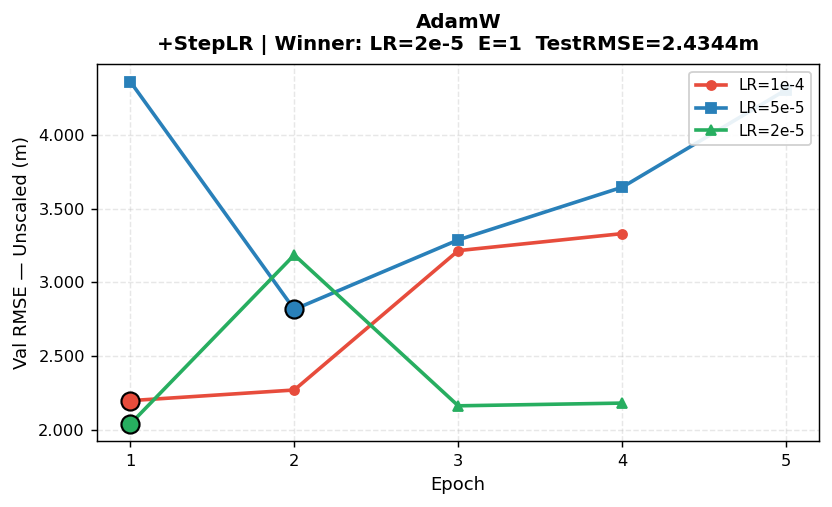

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/optim_epoch_curve_optim_adamw_step.png


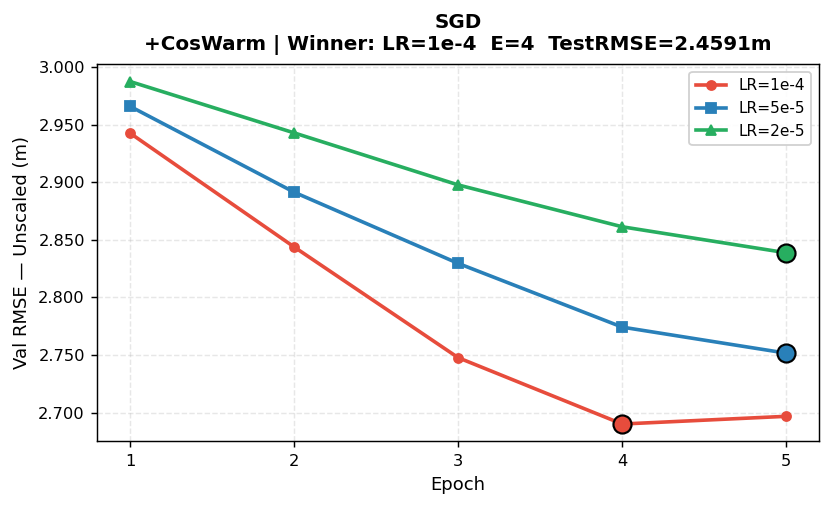

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/optim_epoch_curve_optim_sgd_cosine_warmup.png


In [20]:
# ── 6.1  Epoch-wise val RMSE — individual figure per optim variant
plot_epoch_curves_per_config(group_configs['OPTIM'], 'OPTIM', 'Optimizer/Scheduler')



══════════════════════════════════════════════════════════════════════
  Test RMSE Bar Charts per LR — OPTIMIZER/SCHEDULER
══════════════════════════════════════════════════════════════════════


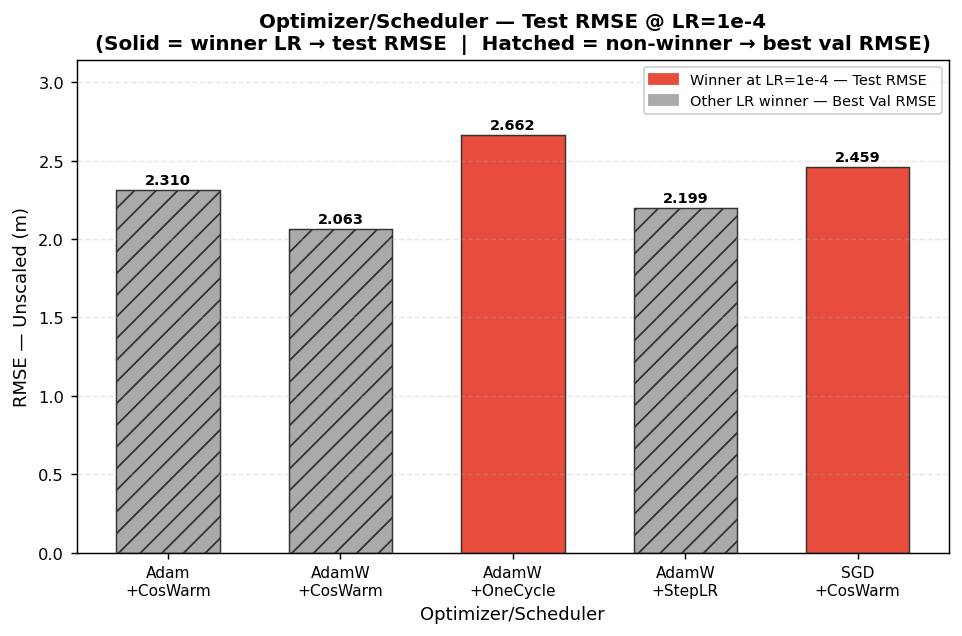

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/optim_bar_test_rmse_lr00001.png


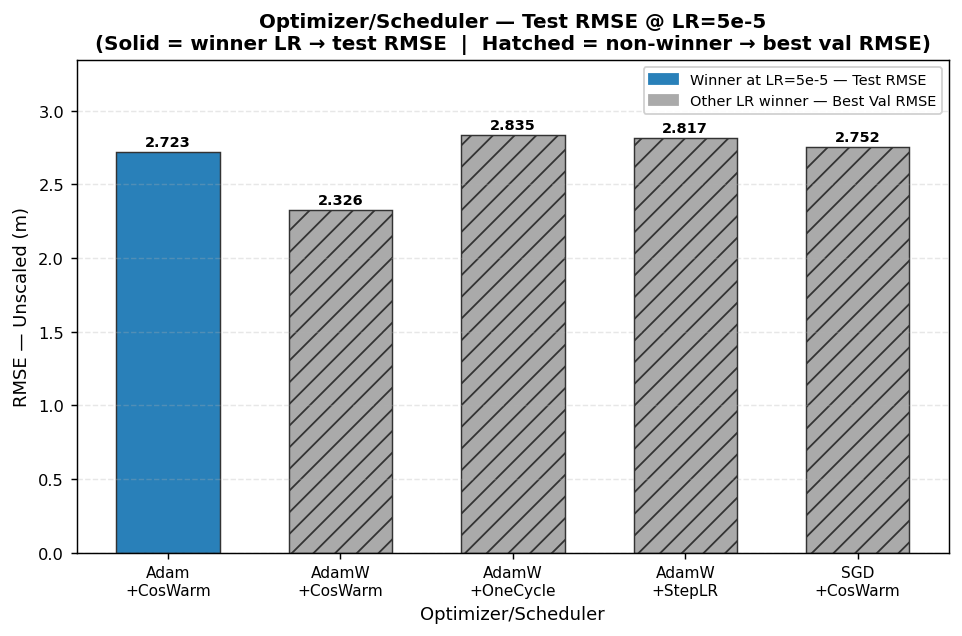

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/optim_bar_test_rmse_lr5e-05.png


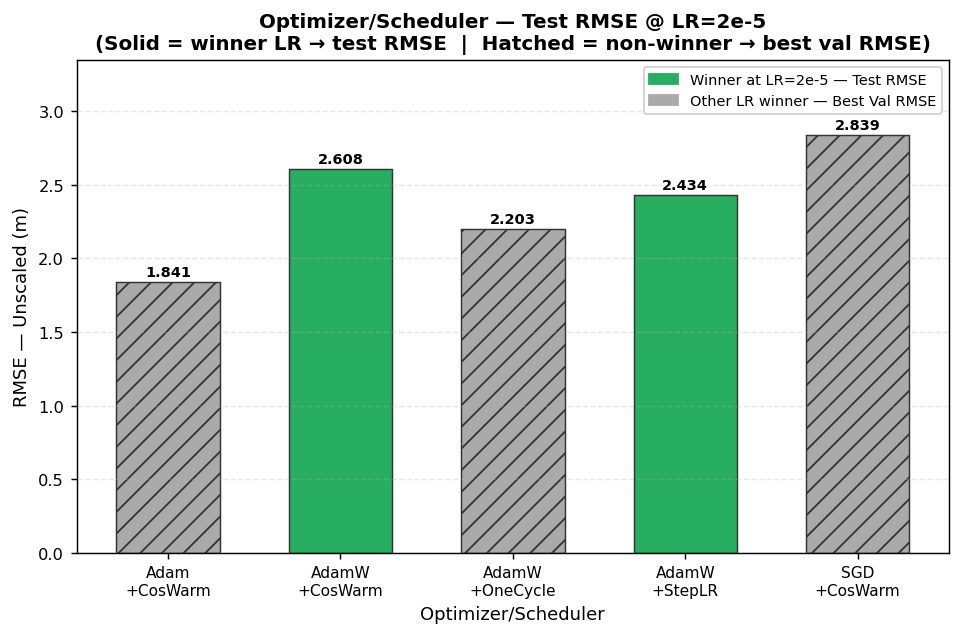

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/optim_bar_test_rmse_lr2e-05.png


In [21]:
# ── 6.2  Bar charts per LR
plot_bar_charts_per_lr(group_configs['OPTIM'], 'OPTIM', 'Optimizer/Scheduler')


In [22]:
# ── 6.3  Trajectory quality table
tdf_optim = trajectory_summary_table(group_configs['OPTIM'], 'Optimizer/Scheduler')



────────────────────────────────────────────────────────────────────────────────
  Trajectory Quality Analysis — OPTIMIZER/SCHEDULER  (Winner LR)
  (Based on val_rmse epoch history at the winning learning rate)
────────────────────────────────────────────────────────────────────────────────


,Winner LR,Best Val RMSE,Winner Epoch,Improv. Rate,Early Stopped,Trend Slope,Test RMSE,Trajectory
Config,,,,,,,,
optim_adam_cosine_warmup,LR=5e-5,1.8065,4/5,50%,No,-0.0620,2.7228,Good Convergence
optim_adamw_cosine_warmup,LR=2e-5,1.8849,3/5,50%,No,-0.0075,2.6078,Good Convergence
optim_adamw_onecycle,LR=1e-4,1.9612,2/5,25%,No,+0.4095,2.6625,Bouncy / Poor
optim_adamw_step,LR=2e-5,2.0406,1/5,33%,⚠ YES,-0.0597,2.4344,Bouncy / Poor
optim_sgd_cosine_warmup,LR=1e-4,2.6902,4/5,75%,No,-0.0645,2.4591,Steady Descent ★


In [23]:
# ── 6.4  Winner declaration
optim_ranked = declare_winner(group_configs['OPTIM'], 'OPTIM', 'Optimizer/Scheduler')



════════════════════════════════════════════════════════════════════════════════
  🏆  OPTIMIZER/SCHEDULER RANKING  (by Test RMSE + Trajectory Quality)
════════════════════════════════════════════════════════════════════════════════


,Short Name,Winner LR,Winner Epoch,Best Val RMSE,Test RMSE ↓,AbsRel ↓,δ<1.25 ↑,Trajectory
Rank,,,,,,,,
1,SGD +CosWarm,LR=1e-4,4,2.690206,2.459052,0.062037,0.975752,Steady Descent ★
2,AdamW +StepLR,LR=2e-5,1,2.040558,2.434434,0.071386,0.971253,Bouncy / Poor
3,AdamW +CosWarm,LR=2e-5,3,1.884869,2.607805,0.075729,0.966410,Good Convergence
4,AdamW +OneCycle,LR=1e-4,2,1.961186,2.662463,0.085048,0.963377,Bouncy / Poor
5,Adam +CosWarm,LR=5e-5,4,1.806509,2.722757,0.077440,0.964958,Good Convergence



🥇  WINNER: [optim_sgd_cosine_warmup]
     Short name  : SGD +CosWarm
     Winner LR   : LR=1e-4
     Winner Epoch: 4/5
     Best Val RMSE: 2.6902 m
     Test RMSE   : 2.4591 m  (pixel-weighted unscaled)
     AbsRel      : 0.0620  |  δ<1.25: 0.9758
     Trajectory  : Steady Descent ★

──────────────────────────────────────────────────  Top-4 Runners-Up  ────────────
  🥈  #2 [optim_adamw_step]
        Test RMSE: 2.4344 m  |  LR: LR=2e-5  |  Epoch: 1  |  Traj: Bouncy / Poor
  🥉  #3 [optim_adamw_cosine_warmup]
        Test RMSE: 2.6078 m  |  LR: LR=2e-5  |  Epoch: 3  |  Traj: Good Convergence
  🏅  #4 [optim_adamw_onecycle]
        Test RMSE: 2.6625 m  |  LR: LR=1e-4  |  Epoch: 2  |  Traj: Bouncy / Poor
  🏅  #5 [optim_adam_cosine_warmup]
        Test RMSE: 2.7228 m  |  LR: LR=5e-5  |  Epoch: 4  |  Traj: Good Convergence


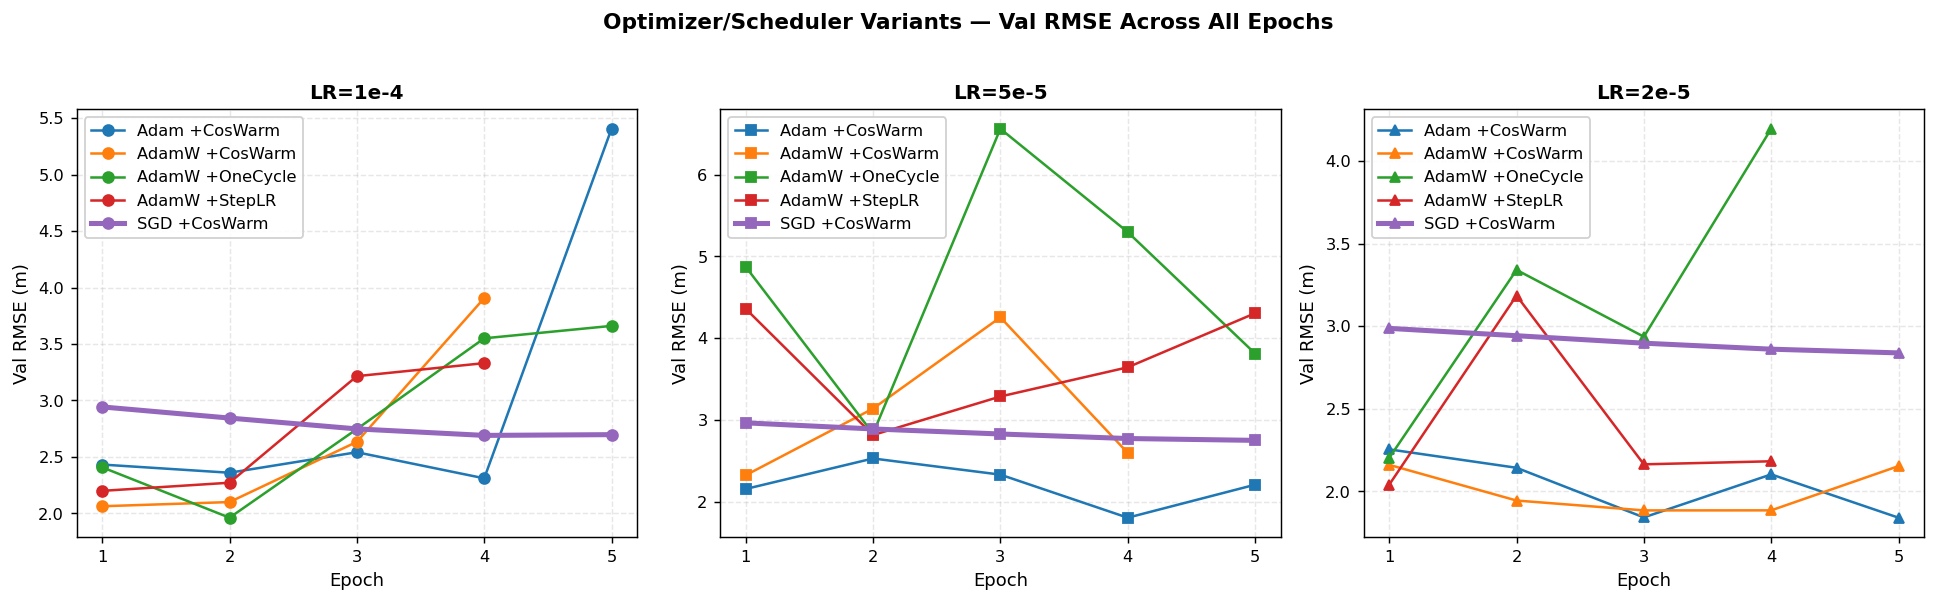

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/OPTIM_overview_all_lrs.png


In [24]:
# ── 6.5  Overview comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=False)
fig.patch.set_facecolor('white')
fig.suptitle("Optimizer/Scheduler Variants — Val RMSE Across All Epochs", 
             fontsize=12, fontweight='bold', y=1.02)

configs = group_configs['OPTIM']
color_map = dict(zip(configs, sns.color_palette("tab10", len(configs))))

for ax, lr_tag in zip(axes, LR_TAGS):
    for cfg in configs:
        df = get_config_history(cfg, lr_tag)
        if df.empty or 'val_rmse' not in df.columns:
            continue
        lw = 2.8 if cfg == optim_ranked.iloc[0]['Config'] else 1.4
        ax.plot(df['epoch'], df['val_rmse'],
                color=color_map[cfg], linewidth=lw,
                marker=LR_MARKERS[lr_tag], markersize=6,
                label=sname(cfg).replace('\n',' '))
    ax.set_title(LR_DISPLAY[lr_tag], fontweight='bold')
    ax.set_xlabel("Epoch"); ax.set_ylabel("Val RMSE (m)")
    ax.set_xticks(range(1, ABLATION_EPOCHS+1))
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.legend(fontsize=9, framealpha=0.9)

plt.tight_layout()
save_and_show(fig, "OPTIM_overview_all_lrs.png")


---
## 7 · Cross-Group Comparison

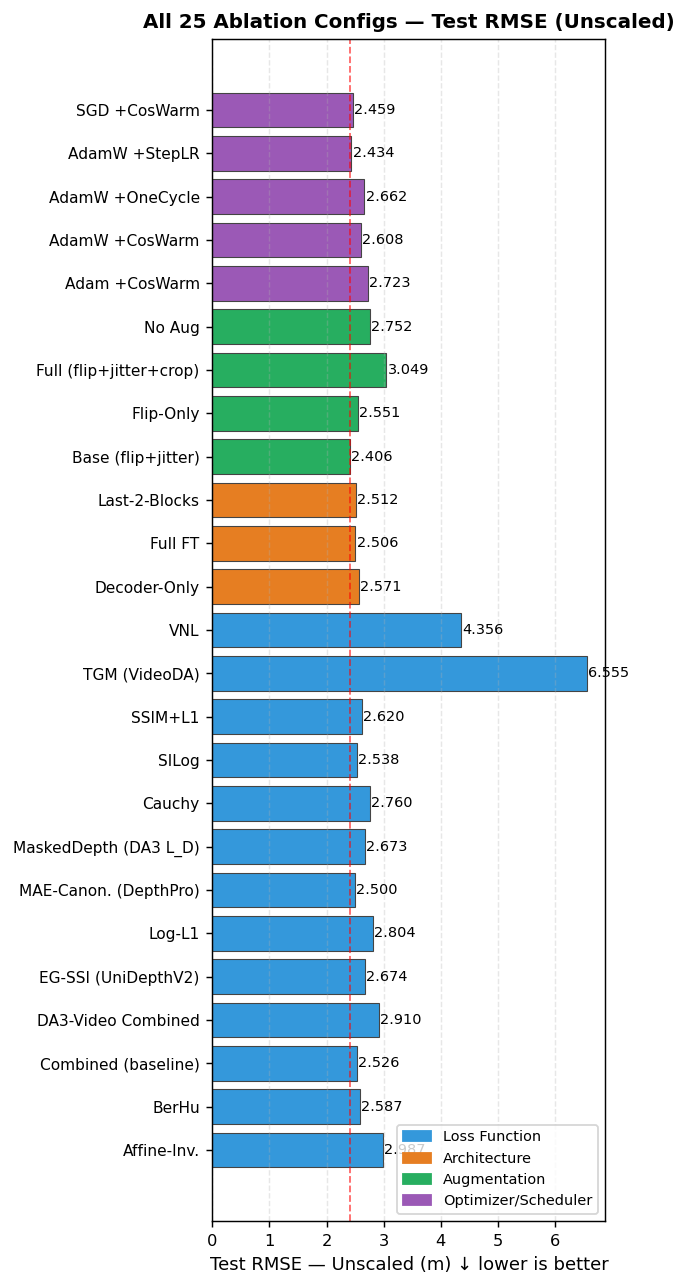

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/ALL_configs_test_rmse_horizontal_bar.png


In [25]:
# ── 7.1  Heatmap: Test RMSE across all 25 configs (grouped) ─────────────────
fig, ax = plt.subplots(figsize=(5, 10))
fig.patch.set_facecolor('white')

all_cfgs = (group_configs['LOSS'] + group_configs['ARCH'] +
            group_configs['AUG'] + group_configs['OPTIM'])
disp_names = [sname(c).replace('\n', ' ') for c in all_cfgs]
rmse_vals  = [summary_df.loc[summary_df['config']==c, 'unscaled_rmse'].values[0]
              if len(summary_df.loc[summary_df['config']==c]) else np.nan
              for c in all_cfgs]

# Horizontal bar chart, sorted within each group
bar_colors_hm = (
    ['#3498db'] * len(group_configs['LOSS']) +
    ['#e67e22'] * len(group_configs['ARCH']) +
    ['#27ae60'] * len(group_configs['AUG'])  +
    ['#9b59b6'] * len(group_configs['OPTIM'])
)

y = np.arange(len(all_cfgs))
bars = ax.barh(y, rmse_vals, color=bar_colors_hm, edgecolor='#444', linewidth=0.6)
for bar, v in zip(bars, rmse_vals):
    if not np.isnan(v):
        ax.text(v + 0.02, bar.get_y() + bar.get_height()/2,
                f'{v:.3f}', va='center', fontsize=8)

ax.set_yticks(y)
ax.set_yticklabels(disp_names, fontsize=8.5)
ax.set_xlabel("Test RMSE — Unscaled (m) ↓ lower is better")
ax.set_title("All 25 Ablation Configs — Test RMSE (Unscaled)", fontweight='bold')
ax.axvline(x=min(v for v in rmse_vals if not np.isnan(v)),
           color='red', linestyle='--', linewidth=1, alpha=0.6, label='Best')
ax.grid(axis='x', alpha=0.3, linestyle='--')

patches = [
    mpatches.Patch(color='#3498db', label='Loss Function'),
    mpatches.Patch(color='#e67e22', label='Architecture'),
    mpatches.Patch(color='#27ae60', label='Augmentation'),
    mpatches.Patch(color='#9b59b6', label='Optimizer/Scheduler'),
]
ax.legend(handles=patches, loc='lower right', fontsize=8)
plt.tight_layout()
save_and_show(fig, "ALL_configs_test_rmse_horizontal_bar.png")


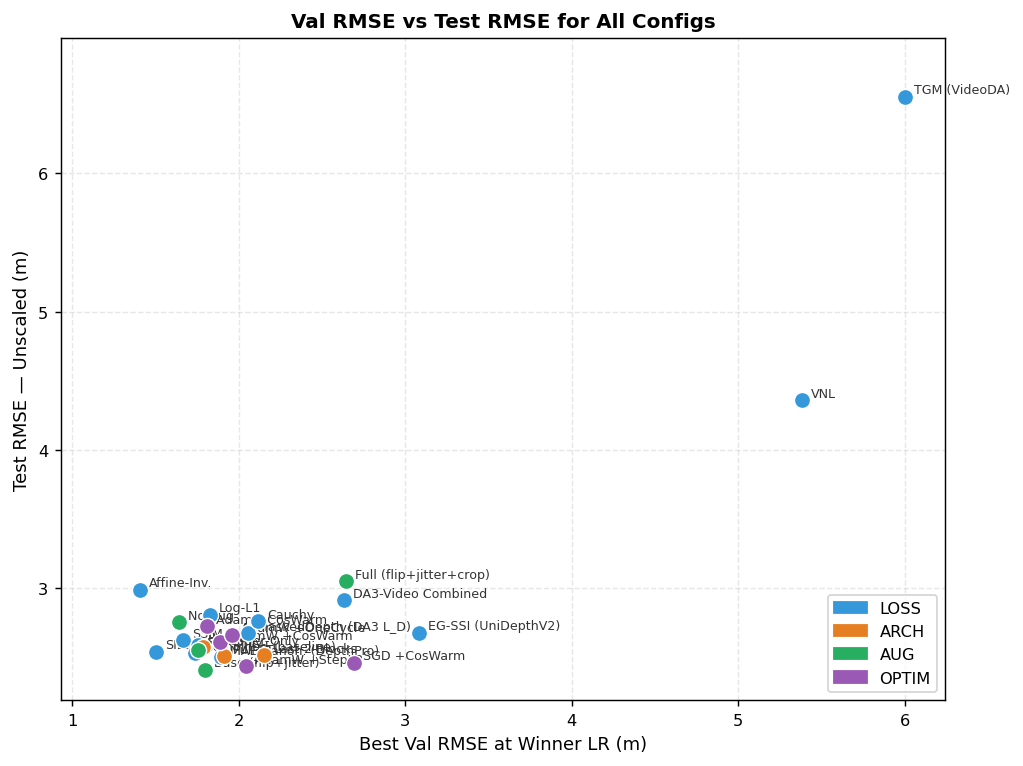

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/ALL_val_vs_test_rmse_scatter.png


In [26]:
# ── 7.2  Scatter: Test RMSE vs Best Val RMSE ─────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))
fig.patch.set_facecolor('white')

group_palette = {
    'LOSS':  '#3498db',
    'ARCH':  '#e67e22',
    'AUG':   '#27ae60',
    'OPTIM': '#9b59b6',
}

for grp, cfgs in group_configs.items():
    for cfg in cfgs:
        row = summary_df[summary_df['config']==cfg]
        if row.empty: continue
        row = row.iloc[0]
        test_r = row.get('unscaled_rmse', np.nan)
        val_r  = row.get('winner_val_rmse', np.nan)
        if np.isnan(test_r) or np.isnan(val_r): continue
        ax.scatter(val_r, test_r, color=group_palette[grp],
                   s=80, edgecolors='white', linewidths=0.8, zorder=4)
        ax.annotate(sname(cfg).replace('\n',' '),
                    (val_r, test_r), textcoords='offset points',
                    xytext=(5, 2), fontsize=7, color='#333')

# Identity line
lim = ax.get_xlim()
ax.plot([min(lim[0], ax.get_ylim()[0])]*2,
        [max(lim[1], ax.get_ylim()[1])]*2, 'k--', alpha=0.3, linewidth=1)

patches = [mpatches.Patch(color=v, label=k) for k,v in group_palette.items()]
ax.legend(handles=patches, fontsize=9)
ax.set_xlabel("Best Val RMSE at Winner LR (m)")
ax.set_ylabel("Test RMSE — Unscaled (m)")
ax.set_title("Val RMSE vs Test RMSE for All Configs", fontweight='bold')
ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
save_and_show(fig, "ALL_val_vs_test_rmse_scatter.png")


---
## 8 · Final Recommendation — Best Combination

In [27]:
# ═══════════════════════════════════════════════════════════════════════════════
# FINAL RECOMMENDATION
# Best loss + best arch + best aug + best optim => recommended training recipe
# ═══════════════════════════════════════════════════════════════════════════════

best_loss  = loss_ranked.iloc[0]
best_arch  = arch_ranked.iloc[0]
best_aug   = aug_ranked.iloc[0]
best_optim = optim_ranked.iloc[0]

print("=" * 80)
print("  ★  BEST COMBINATION RECOMMENDATION  ★")
print("  DA3METRIC-LARGE · Fully-Supervised Fine-Tuning · KITTI Eigen-Split")
print("=" * 80)

print(f"""
╔══════════════════════════════════════════════════════════════════════════════╗
║  COMPONENT        BEST CHOICE                          TEST RMSE (isolated) ║
╠══════════════════════════════════════════════════════════════════════════════╣
║  Loss Function  : {best_loss['Config']:<35}  {best_loss['Test RMSE ↓']:.4f} m          ║
║  Architecture   : {best_arch['Config']:<35}  {best_arch['Test RMSE ↓']:.4f} m          ║
║  Augmentation   : {best_aug['Config']:<35}  {best_aug['Test RMSE ↓']:.4f} m          ║
║  Optimizer/Sched: {best_optim['Config']:<35}  {best_optim['Test RMSE ↓']:.4f} m          ║
╠══════════════════════════════════════════════════════════════════════════════╣
║  Learning Rates : Loss  → {best_loss['Winner LR']:<10}                                  ║
║                   Arch  → {best_arch['Winner LR']:<10}                                  ║
║                   Aug   → {best_aug['Winner LR']:<10}                                  ║
║                   Optim → {best_optim['Winner LR']:<10}                                  ║
╚══════════════════════════════════════════════════════════════════════════════╝
""")

print("─" * 80)
print("RATIONALE:")
print(f"  Loss  : {best_loss['Config']} — Test RMSE={best_loss['Test RMSE ↓']:.4f} m, "
      f"Traj={best_loss['Trajectory']}")
print(f"  Arch  : {best_arch['Config']} — Test RMSE={best_arch['Test RMSE ↓']:.4f} m, "
      f"Traj={best_arch['Trajectory']}")
print(f"  Aug   : {best_aug['Config']} — Test RMSE={best_aug['Test RMSE ↓']:.4f} m, "
      f"Traj={best_aug['Trajectory']}")
print(f"  Optim : {best_optim['Config']} — Test RMSE={best_optim['Test RMSE ↓']:.4f} m, "
      f"Traj={best_optim['Trajectory']}")

print()
print("NOTE: The winners above were selected from isolated ablations.")
print("Combining all four best choices in a single run may produce")
print("slightly different (hopefully better) results due to synergies.")
print()

# ── Recommended LR ──────────────────────────────────────────────────────────
from collections import Counter
lr_votes = Counter([best_loss['Winner LR'], best_arch['Winner LR'],
                    best_aug['Winner LR'], best_optim['Winner LR']])
recommended_lr = lr_votes.most_common(1)[0][0]
print(f"Recommended LR for combined run: {recommended_lr}  (majority vote from ablations)")
print("=" * 80)


  ★  BEST COMBINATION RECOMMENDATION  ★
  DA3METRIC-LARGE · Fully-Supervised Fine-Tuning · KITTI Eigen-Split

╔══════════════════════════════════════════════════════════════════════════════╗
║  COMPONENT        BEST CHOICE                          TEST RMSE (isolated) ║
╠══════════════════════════════════════════════════════════════════════════════╣
║  Loss Function  : loss_mae_canonical                   2.4997 m          ║
║  Architecture   : arch_last2_blocks                    2.5124 m          ║
║  Augmentation   : aug_base                             2.4064 m          ║
║  Optimizer/Sched: optim_sgd_cosine_warmup              2.4591 m          ║
╠══════════════════════════════════════════════════════════════════════════════╣
║  Learning Rates : Loss  → LR=5e-5                                     ║
║                   Arch  → LR=5e-5                                     ║
║                   Aug   → LR=2e-5                                     ║
║                   Optim → LR=1e-4  

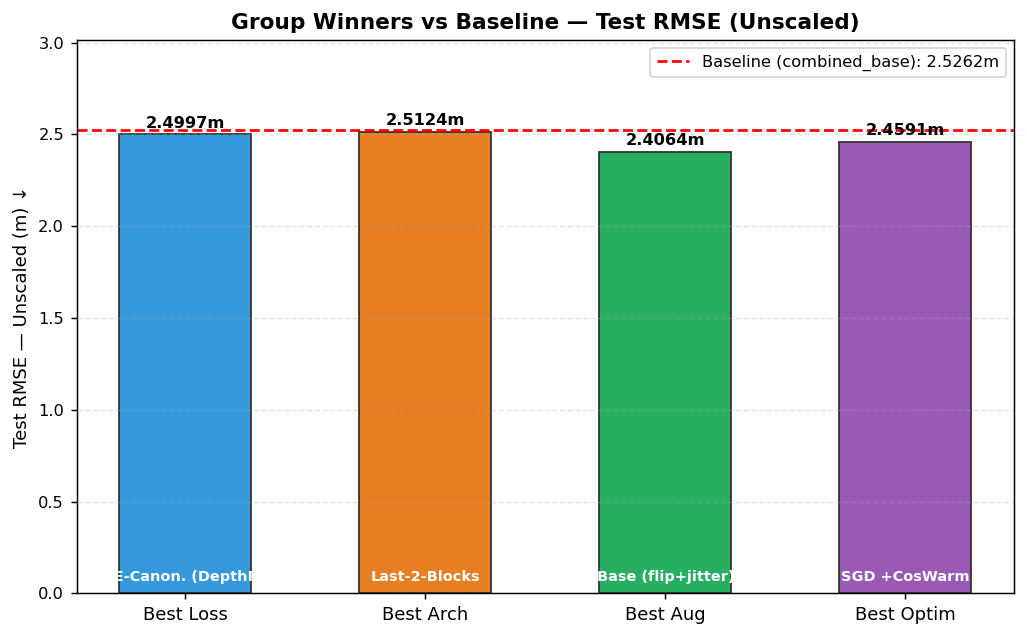

  ✓ Saved → /STORAGE/Arka/a_MDE_Code/5_Fully_supervised_FT/super_ft_ablation_outputs/analysis/FINAL_group_winners_summary.png


In [28]:
# ── Final summary bar chart: winners of each group ───────────────────────────
winners = {
    'Best Loss':       (best_loss['Config'],  best_loss['Test RMSE ↓'],  '#3498db'),
    'Best Arch':       (best_arch['Config'],  best_arch['Test RMSE ↓'],  '#e67e22'),
    'Best Aug':        (best_aug['Config'],   best_aug['Test RMSE ↓'],   '#27ae60'),
    'Best Optim':      (best_optim['Config'], best_optim['Test RMSE ↓'], '#9b59b6'),
}

# Also include combined_base baseline for reference
baseline = summary_df.loc[summary_df['config']=='loss_combined_base', 'unscaled_rmse']
baseline_val = float(baseline.values[0]) if len(baseline) else np.nan

fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor('white')

labels = list(winners.keys())
heights = [v[1] for v in winners.values()]
colors  = [v[2] for v in winners.values()]
cfgs    = [v[0] for v in winners.values()]

x = np.arange(len(labels))
bars = ax.bar(x, heights, color=colors, edgecolor='#333', linewidth=1, width=0.55)

for bar, h, cfg in zip(bars, heights, cfgs):
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.02,
            f'{h:.4f}m', ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.text(bar.get_x() + bar.get_width()/2, 0.05,
            sname(cfg).replace('\n',' '), ha='center', va='bottom',
            fontsize=8, color='white', fontweight='bold',
            rotation=0)

# Baseline reference line
ax.axhline(y=baseline_val, color='red', linestyle='--', linewidth=1.5,
           label=f'Baseline (combined_base): {baseline_val:.4f}m')

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylabel("Test RMSE — Unscaled (m) ↓", fontsize=10)
ax.set_title("Group Winners vs Baseline — Test RMSE (Unscaled)",
             fontweight='bold', fontsize=12)
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_ylim(0, max(heights) * 1.2)
plt.tight_layout()
save_and_show(fig, "FINAL_group_winners_summary.png")


In [29]:
# ── Loss-function detailed runner-up ranking (top 5) ────────────────────────
print("\n" + "="*80)
print("  DETAILED TOP-5 RANKING — LOSS FUNCTION")
print("  Criteria: test_rmse ↓, then trajectory quality (Steady Descent preferred)")
print("="*80)

top5_loss = loss_ranked.head(5)
for i, row in top5_loss.iterrows():
    medal = ["🥇","🥈","🥉","🏅","🏅"][i]
    print(f"  {medal} #{i+1}  {row['Config']:<30}  "
          f"TestRMSE={row['Test RMSE ↓']:.4f}m  "
          f"LR={row['Winner LR']:8s}  "
          f"E={row['Winner Epoch']}/{ABLATION_EPOCHS}  "
          f"{row['Trajectory']}")

print("\n" + "="*80)
print("  DETAILED TOP-5 RANKING — ARCHITECTURE")
print("="*80)
top5_arch = arch_ranked.head(min(5, len(arch_ranked)))
for i, row in top5_arch.iterrows():
    medal = ["🥇","🥈","🥉","🏅","🏅"][min(i,4)]
    print(f"  {medal} #{i+1}  {row['Config']:<30}  "
          f"TestRMSE={row['Test RMSE ↓']:.4f}m  "
          f"LR={row['Winner LR']:8s}  "
          f"E={row['Winner Epoch']}/{ABLATION_EPOCHS}  "
          f"{row['Trajectory']}")

print("\n" + "="*80)
print("  DETAILED TOP-5 RANKING — AUGMENTATION")
print("="*80)
top5_aug = aug_ranked.head(min(5, len(aug_ranked)))
for i, row in top5_aug.iterrows():
    medal = ["🥇","🥈","🥉","🏅","🏅"][min(i,4)]
    print(f"  {medal} #{i+1}  {row['Config']:<30}  "
          f"TestRMSE={row['Test RMSE ↓']:.4f}m  "
          f"LR={row['Winner LR']:8s}  "
          f"E={row['Winner Epoch']}/{ABLATION_EPOCHS}  "
          f"{row['Trajectory']}")

print("\n" + "="*80)
print("  DETAILED TOP-5 RANKING — OPTIMIZER/SCHEDULER")
print("="*80)
top5_optim = optim_ranked.head(min(5, len(optim_ranked)))
for i, row in top5_optim.iterrows():
    medal = ["🥇","🥈","🥉","🏅","🏅"][min(i,4)]
    print(f"  {medal} #{i+1}  {row['Config']:<30}  "
          f"TestRMSE={row['Test RMSE ↓']:.4f}m  "
          f"LR={row['Winner LR']:8s}  "
          f"E={row['Winner Epoch']}/{ABLATION_EPOCHS}  "
          f"{row['Trajectory']}")

print("\n  ✓ Analysis complete. All plots saved to:", PLOT_DIR)



  DETAILED TOP-5 RANKING — LOSS FUNCTION
  Criteria: test_rmse ↓, then trajectory quality (Steady Descent preferred)
  🥇 #1  loss_mae_canonical              TestRMSE=2.4997m  LR=LR=5e-5   E=3/5  Good Convergence
  🥈 #2  loss_combined_base              TestRMSE=2.5262m  LR=LR=2e-5   E=4/5  Steady Descent ★
  🥉 #3  loss_silog                      TestRMSE=2.5376m  LR=LR=2e-5   E=5/5  Steady Descent ★
  🏅 #4  loss_berhu                      TestRMSE=2.5868m  LR=LR=5e-5   E=5/5  Steady Descent ★
  🏅 #5  loss_ssim_l1                    TestRMSE=2.6201m  LR=LR=5e-5   E=4/5  Good Convergence

  DETAILED TOP-5 RANKING — ARCHITECTURE
  🥇 #1  arch_last2_blocks               TestRMSE=2.5124m  LR=LR=5e-5   E=5/5  Steady Descent ★
  🥈 #2  arch_decoder_only               TestRMSE=2.5714m  LR=LR=2e-5   E=5/5  Steady Descent ★
  🥉 #3  arch_full                       TestRMSE=2.5056m  LR=LR=2e-5   E=1/5  Bouncy / Poor

  DETAILED TOP-5 RANKING — AUGMENTATION
  🥇 #1  aug_base                        Tes